In [3]:
import os
import matplotlib.pyplot as plt
import random
from PIL import Image

dataset_path = r"C:\Users\hp\Downloads\Processed Data"

for root, dirs, files in os.walk(dataset_path):
    print(root, "->", len(files), "images")

C:\Users\hp\Downloads\Processed Data -> 0 images
C:\Users\hp\Downloads\Processed Data\Processed Data -> 0 images
C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Banana(1-4) -> 590 images
C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Bittermelon(1-3) -> 590 images
C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Cucumber(1-6) -> 590 images
C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh eggplant(1-4) -> 590 images
C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Orange(1-9) -> 590 images
C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Papaya(1-4) -> 590 images
C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh pineapple(1-15) -> 590 images
C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Tomato(1-10) -> 590 images
C:\Users\hp\Downloads\Processed Data\Processed Data\Rotten banana(7-13) -> 590 images
C:\Users\hp\Downloads\Processed Data\Processed Data\Rotten Bittermelon(5-8) -> 590 images
C:\Users\hp\Downloads\Pro

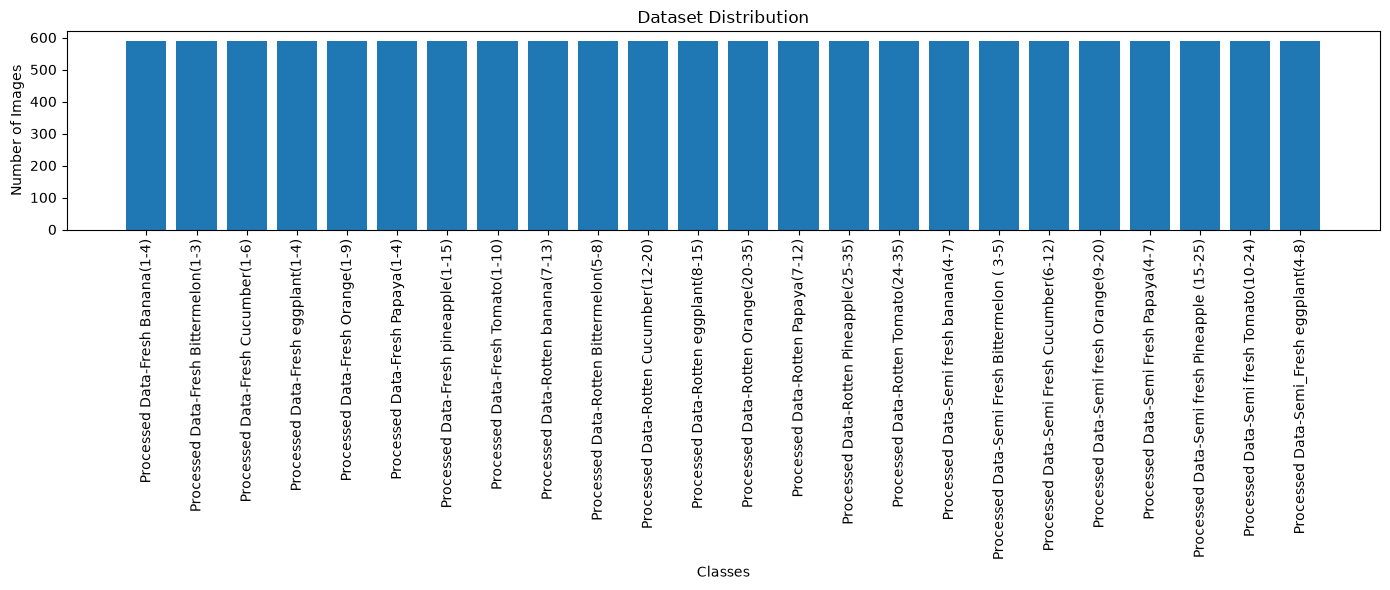

In [18]:
classes = []
counts = []

for food in os.listdir(dataset_path):
    food_path = os.path.join(dataset_path, food)

    if os.path.isdir(food_path):
        for freshness in os.listdir(food_path):
            folder = os.path.join(food_path, freshness)

            if os.path.isdir(folder):
                classes.append(f"{food}-{freshness}")
                counts.append(len(os.listdir(folder)))

plt.figure(figsize=(14, 6))
plt.bar(classes, counts)

plt.xticks(rotation=90)
plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.title("Dataset Distribution")

plt.tight_layout()
plt.show()

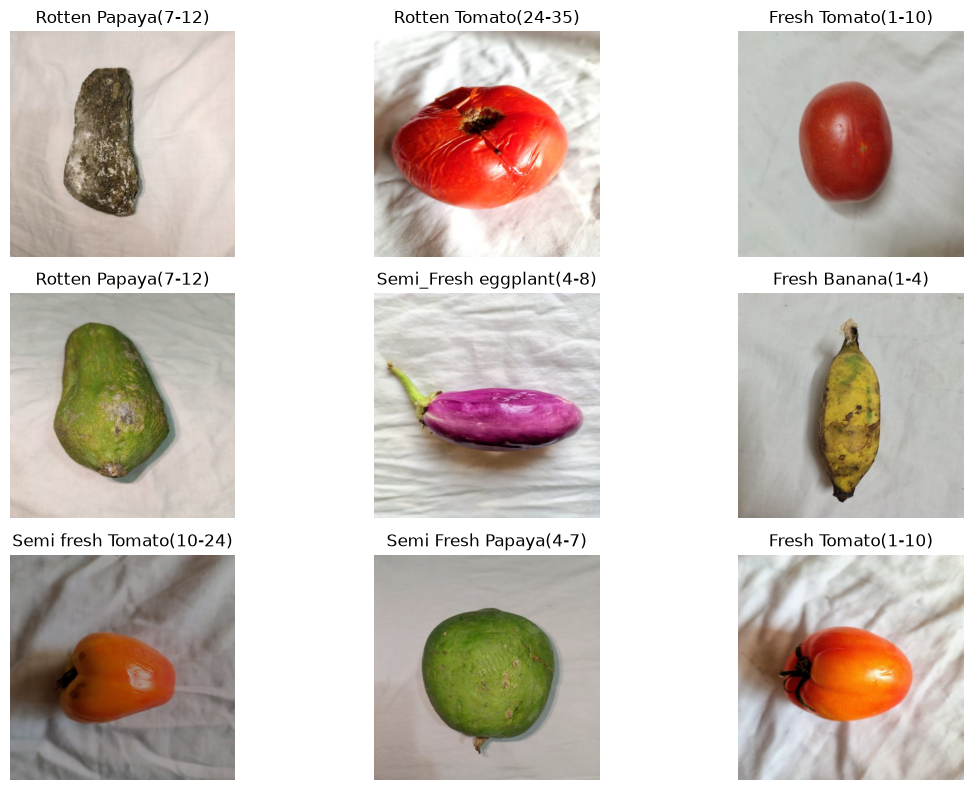

In [19]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = r"C:\Users\hp\Downloads\Processed Data\Processed Data"

classes = [
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
]

plt.figure(figsize=(12, 8))

for i in range(9):
    class_name = random.choice(classes)

    folder = os.path.join(dataset_path, class_name)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp'))
        and os.path.isfile(os.path.join(folder, f))
    ]

    image_name = random.choice(images)
    image_path = os.path.join(folder, image_name)

    img = Image.open(image_path).convert("RGB")

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
import os
from PIL import Image

dimensions = []

for class_name in classes:
    folder = os.path.join(dataset_path, class_name)

    for file in os.listdir(folder):
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')):
            path = os.path.join(folder, file)

            try:
                img = Image.open(path)
                dimensions.append(img.size)
            except Exception:
                pass

print("Total images:", len(dimensions))
print("Sample dimensions:", dimensions[:10])

Total images: 14160
Sample dimensions: [(512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512), (512, 512)]


In [21]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

print("Number of classes:", len(class_names))
print("Classes:", class_names)

Found 14160 files belonging to 24 classes.
Using 9912 files for training.
Found 14160 files belonging to 24 classes.
Using 4248 files for validation.
Number of classes: 24
Classes: ['Fresh Banana(1-4)', 'Fresh Bittermelon(1-3)', 'Fresh Cucumber(1-6)', 'Fresh Orange(1-9)', 'Fresh Papaya(1-4)', 'Fresh Tomato(1-10)', 'Fresh eggplant(1-4)', 'Fresh pineapple(1-15)', 'Rotten Bittermelon(5-8)', 'Rotten Cucumber(12-20)', 'Rotten Orange(20-35)', 'Rotten Papaya(7-12)', 'Rotten Pineapple(25-35)', 'Rotten Tomato(24-35)', 'Rotten banana(7-13)', 'Rotten eggplant(8-15)', 'Semi Fresh Bittermelon ( 3-5)', 'Semi Fresh Cucumber(6-12)', 'Semi Fresh Papaya(4-7)', 'Semi fresh Orange(9-20)', 'Semi fresh Pineapple (15-25)', 'Semi fresh Tomato(10-24)', 'Semi fresh banana(4-7)', 'Semi_Fresh eggplant(4-8)']


In [22]:
# Split temporary dataset into validation and testing

temp_ds = temp_ds.unbatch()

temp_ds = temp_ds.shuffle(
    4248,
    seed=42,
    reshuffle_each_iteration=False
)

val_ds = temp_ds.take(2124).batch(BATCH_SIZE)

test_ds = temp_ds.skip(2124).batch(BATCH_SIZE)

print("Training images:", 9912)
print("Validation images:", 2124)
print("Testing images:", 2124)

Training images: 9912
Validation images: 2124
Testing images: 2124


In [23]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

test_ds = test_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

In [24]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [149]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

In [150]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    GlobalAveragePooling2D, Dense, Dropout
)

model = Sequential([
    Input(shape=(224, 224, 3)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(24, activation='softmax')
])

In [151]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [152]:
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,856 (440.84 KB)

 Trainable params: 112,856 (440.84 KB)

 Non-trainable params: 0 (0.00 B)

In [153]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    'best_food_model.keras',
    monitor='val_loss',
    save_best_only=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=0.00001
)

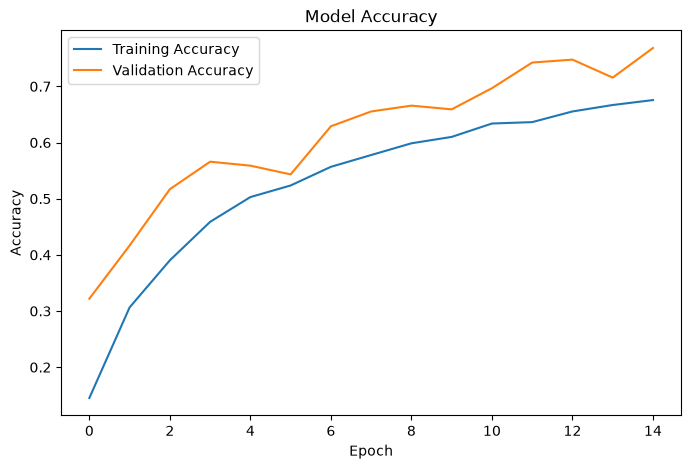

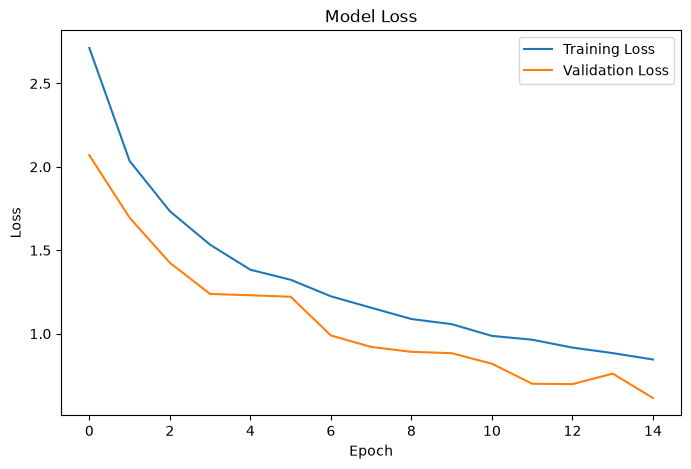

In [ ]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

67/67 ━━━━━━━━━━━━━━━━━━━━ 26s 343ms/step - accuracy: 0.0438 - loss: 3.1791
Test Accuracy: 4.38 %
Test Loss: 3.1791


In [ ]:
import numpy as np

def check_distribution(dataset, name):
    counts = np.zeros(24, dtype=int)

    for images, labels in dataset:
        counts += np.bincount(
            labels.numpy(),
            minlength=24
        )

    print(f"\n{name} distribution:")
    for i, count in enumerate(counts):
        print(class_names[i], ":", count)

    print("Total images:", counts.sum())


check_distribution(train_ds, "Training")
check_distribution(val_ds, "Validation")
check_distribution(test_ds, "Testing")


Training distribution:
Fresh Banana(1-4) : 429
Fresh Bittermelon(1-3) : 413
Fresh Cucumber(1-6) : 422
Fresh Orange(1-9) : 412
Fresh Papaya(1-4) : 422
Fresh Tomato(1-10) : 418
Fresh eggplant(1-4) : 422
Fresh pineapple(1-15) : 425
Rotten Bittermelon(5-8) : 417
Rotten Cucumber(12-20) : 420
Rotten Orange(20-35) : 410
Rotten Papaya(7-12) : 402
Rotten Pineapple(25-35) : 400
Rotten Tomato(24-35) : 414
Rotten banana(7-13) : 430
Rotten eggplant(8-15) : 420
Semi Fresh Bittermelon ( 3-5) : 416
Semi Fresh Cucumber(6-12) : 400
Semi Fresh Papaya(4-7) : 401
Semi fresh Orange(9-20) : 395
Semi fresh Pineapple (15-25) : 390
Semi fresh Tomato(10-24) : 433
Semi fresh banana(4-7) : 392
Semi_Fresh eggplant(4-8) : 409
Total images: 9912

Validation distribution:
Fresh Banana(1-4) : 76
Fresh Bittermelon(1-3) : 93
Fresh Cucumber(1-6) : 84
Fresh Orange(1-9) : 105
Fresh Papaya(1-4) : 86
Fresh Tomato(1-10) : 83
Fresh eggplant(1-4) : 77
Fresh pineapple(1-15) : 88
Rotten Bittermelon(5-8) : 87
Rotten Cucumber(12-20

In [ ]:
images, labels = next(iter(test_ds))

predictions = model.predict(images)

predicted_classes = np.argmax(predictions, axis=1)

for i in range(10):
    print(
        "Actual:", class_names[labels[i].numpy()],
        "| Predicted:", class_names[predicted_classes[i]]
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step
Actual: Semi fresh Tomato(10-24) | Predicted: Rotten Tomato(24-35)
Actual: Semi fresh banana(4-7) | Predicted: Rotten Tomato(24-35)
Actual: Rotten Tomato(24-35) | Predicted: Rotten Tomato(24-35)
Actual: Rotten Bittermelon(5-8) | Predicted: Rotten Tomato(24-35)
Actual: Rotten banana(7-13) | Predicted: Rotten Tomato(24-35)
Actual: Rotten eggplant(8-15) | Predicted: Rotten Tomato(24-35)
Actual: Fresh Banana(1-4) | Predicted: Rotten Tomato(24-35)
Actual: Fresh Banana(1-4) | Predicted: Rotten Tomato(24-35)
Actual: Semi Fresh Cucumber(6-12) | Predicted: Rotten Tomato(24-35)
Actual: Fresh Banana(1-4) | Predicted: Rotten Tomato(24-35)


In [160]:
val_loss, val_accuracy = model.evaluate(val_ds)
test_loss, test_accuracy = model.evaluate(test_ds)

print("Validation Accuracy:", val_accuracy * 100)
print("Test Accuracy:", test_accuracy * 100)

67/67 ━━━━━━━━━━━━━━━━━━━━ 14s 165ms/step - accuracy: 0.2679 - loss: 2.1726
67/67 ━━━━━━━━━━━━━━━━━━━━ 13s 153ms/step - accuracy: 0.2721 - loss: 2.1473
Validation Accuracy: 26.78907811641693
Test Accuracy: 27.212804555892944


In [161]:
val_images, val_labels = next(iter(val_ds))
test_images, test_labels = next(iter(test_ds))

print("Validation range:",
      tf.reduce_min(val_images).numpy(),
      tf.reduce_max(val_images).numpy())

print("Testing range:",
      tf.reduce_min(test_images).numpy(),
      tf.reduce_max(test_images).numpy())

Validation range: 0.0 1.0
Testing range: 0.0 1.0


In [162]:
print("Best validation accuracy:",
      max(history.history['val_accuracy']) * 100, "%")

print("Last epoch validation accuracy:",
      history.history['val_accuracy'][-1] * 100, "%")

print("Current validation accuracy:",
      val_accuracy * 100, "%")

Best validation accuracy: 76.83615684509277 %
Last epoch validation accuracy: 76.83615684509277 %
Current validation accuracy: 26.78907811641693 %


In [163]:
from tensorflow.keras.models import load_model

best_model = load_model('best_food_model.keras')

val_loss, val_accuracy = best_model.evaluate(val_ds)
test_loss, test_accuracy = best_model.evaluate(test_ds)

print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

67/67 ━━━━━━━━━━━━━━━━━━━━ 14s 163ms/step - accuracy: 0.7604 - loss: 0.6235
67/67 ━━━━━━━━━━━━━━━━━━━━ 13s 159ms/step - accuracy: 0.7514 - loss: 0.6442
Validation Accuracy: 76.04 %
Test Accuracy: 75.14 %


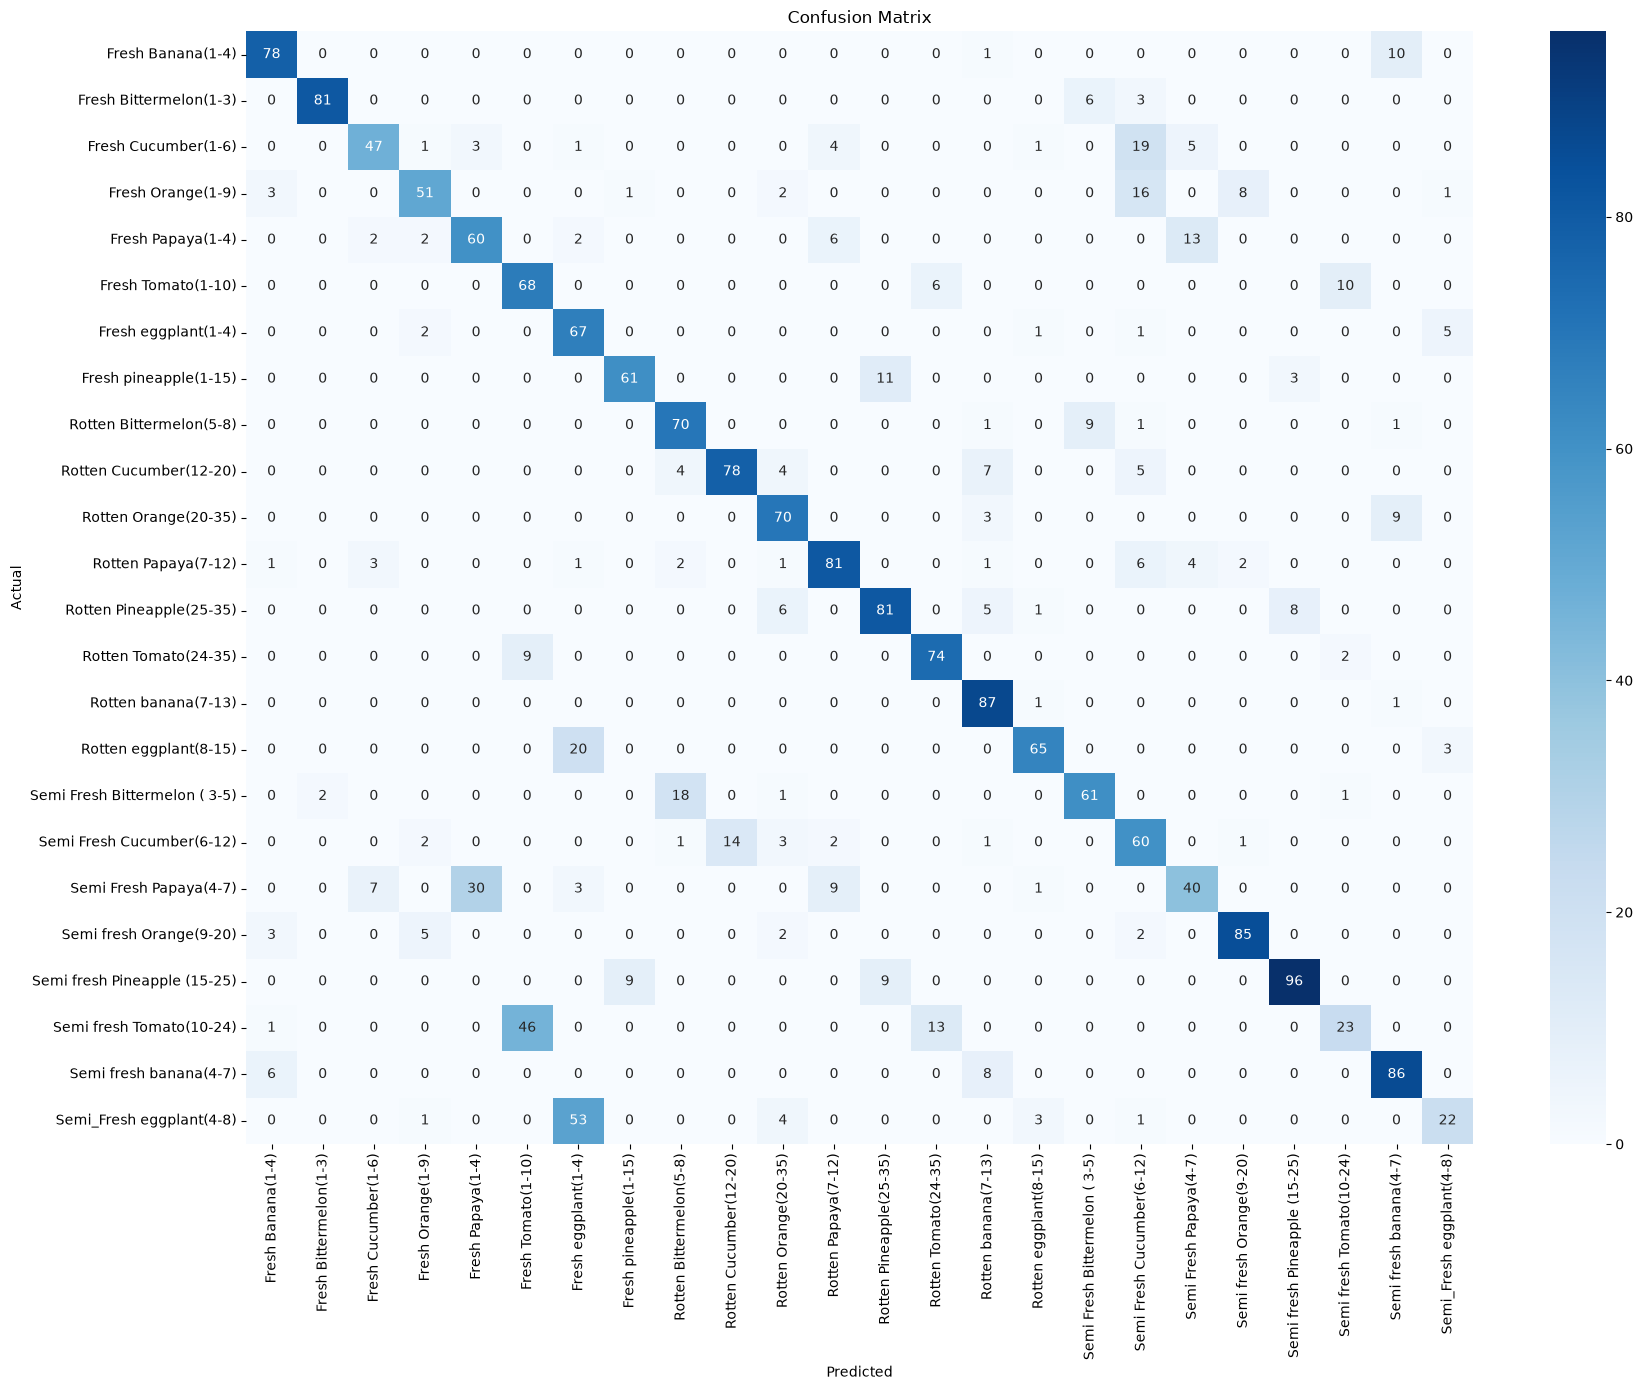

In [164]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = best_model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(18, 14))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names,
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [166]:
import pandas as pd
import numpy as np

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

for i, class_name in enumerate(class_names):
    row = cm[i].copy()
    row[i] = 0

    j = np.argmax(row)

    if row[j] > 0:
        print(
            f"{class_name} → {class_names[j]}: "
            f"{row[j]} images"
        )

Fresh Banana(1-4) → Semi fresh banana(4-7): 10 images
Fresh Bittermelon(1-3) → Semi Fresh Bittermelon ( 3-5): 6 images
Fresh Cucumber(1-6) → Semi Fresh Cucumber(6-12): 19 images
Fresh Orange(1-9) → Semi Fresh Cucumber(6-12): 16 images
Fresh Papaya(1-4) → Semi Fresh Papaya(4-7): 13 images
Fresh Tomato(1-10) → Semi fresh Tomato(10-24): 10 images
Fresh eggplant(1-4) → Semi_Fresh eggplant(4-8): 5 images
Fresh pineapple(1-15) → Rotten Pineapple(25-35): 11 images
Rotten Bittermelon(5-8) → Semi Fresh Bittermelon ( 3-5): 9 images
Rotten Cucumber(12-20) → Rotten banana(7-13): 7 images
Rotten Orange(20-35) → Semi fresh banana(4-7): 9 images
Rotten Papaya(7-12) → Semi Fresh Cucumber(6-12): 6 images
Rotten Pineapple(25-35) → Semi fresh Pineapple (15-25): 8 images
Rotten Tomato(24-35) → Fresh Tomato(1-10): 9 images
Rotten banana(7-13) → Rotten eggplant(8-15): 1 images
Rotten eggplant(8-15) → Fresh eggplant(1-4): 20 images
Semi Fresh Bittermelon ( 3-5) → Rotten Bittermelon(5-8): 18 images
Semi Fresh

In [167]:
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

                               precision    recall  f1-score   support

            Fresh Banana(1-4)       0.85      0.88      0.86        89
       Fresh Bittermelon(1-3)       0.98      0.90      0.94        90
          Fresh Cucumber(1-6)       0.80      0.58      0.67        81
            Fresh Orange(1-9)       0.80      0.62      0.70        82
            Fresh Papaya(1-4)       0.65      0.71      0.67        85
           Fresh Tomato(1-10)       0.55      0.81      0.66        84
          Fresh eggplant(1-4)       0.46      0.88      0.60        76
        Fresh pineapple(1-15)       0.86      0.81      0.84        75
      Rotten Bittermelon(5-8)       0.74      0.85      0.79        82
       Rotten Cucumber(12-20)       0.85      0.80      0.82        98
         Rotten Orange(20-35)       0.75      0.85      0.80        82
          Rotten Papaya(7-12)       0.79      0.79      0.79       102
      Rotten Pineapple(25-35)       0.80      0.80      0.80       101
     

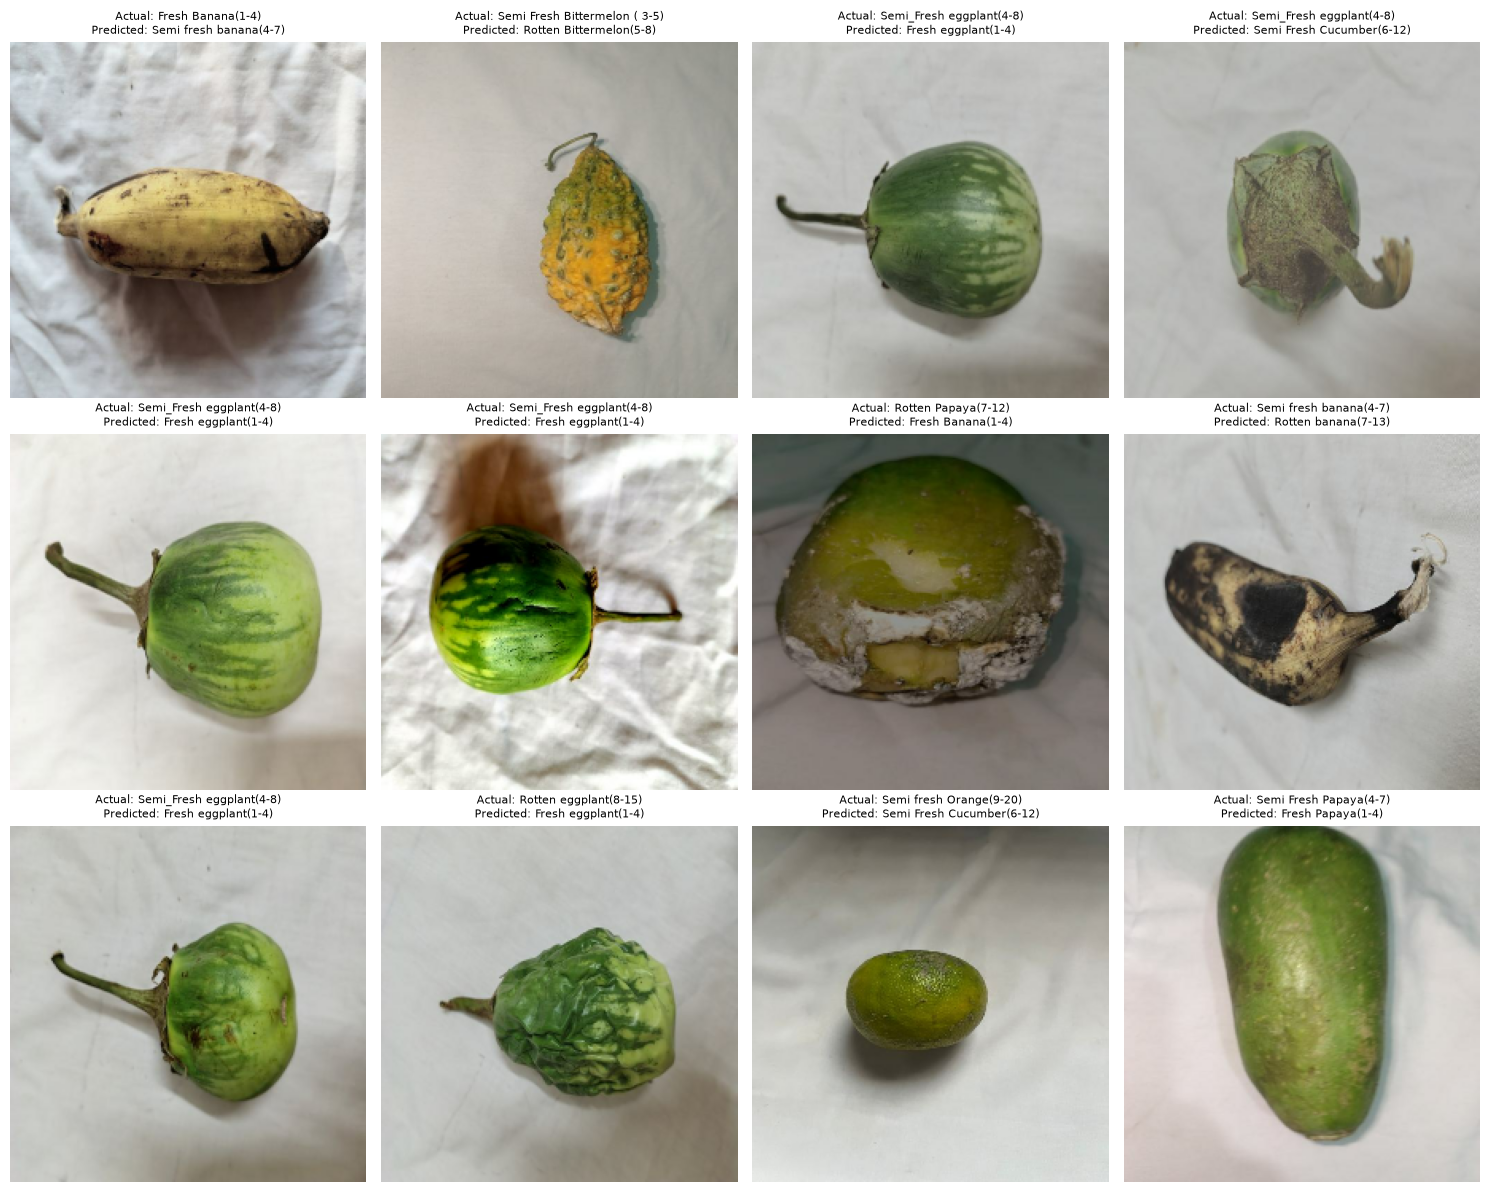

In [168]:
import matplotlib.pyplot as plt
import numpy as np

misclassified = []

for images, labels in test_ds:
    predictions = best_model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)

    for i in range(len(labels)):
        if labels[i].numpy() != predicted_labels[i]:
            misclassified.append((
                images[i].numpy(),
                labels[i].numpy(),
                predicted_labels[i]
            ))

# Display first 12 incorrect predictions
plt.figure(figsize=(15, 12))

for i in range(min(12, len(misclassified))):
    image, actual, predicted = misclassified[i]

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"Actual: {class_names[actual]}\n"
        f"Predicted: {class_names[predicted]}",
        fontsize=8
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

In [169]:
for i, name in enumerate(class_names):
    correct = cm[i][i]
    total = cm[i].sum()
    incorrect = total - correct

    print(f"{name}")
    print(f"  Correct: {correct}/{total}")
    print(f"  Incorrect: {incorrect}/{total}")
    print(f"  Accuracy: {correct/total*100:.2f}%")
    print()

Fresh Banana(1-4)
  Correct: 78/89
  Incorrect: 11/89
  Accuracy: 87.64%

Fresh Bittermelon(1-3)
  Correct: 81/90
  Incorrect: 9/90
  Accuracy: 90.00%

Fresh Cucumber(1-6)
  Correct: 47/81
  Incorrect: 34/81
  Accuracy: 58.02%

Fresh Orange(1-9)
  Correct: 51/82
  Incorrect: 31/82
  Accuracy: 62.20%

Fresh Papaya(1-4)
  Correct: 60/85
  Incorrect: 25/85
  Accuracy: 70.59%

Fresh Tomato(1-10)
  Correct: 68/84
  Incorrect: 16/84
  Accuracy: 80.95%

Fresh eggplant(1-4)
  Correct: 67/76
  Incorrect: 9/76
  Accuracy: 88.16%

Fresh pineapple(1-15)
  Correct: 61/75
  Incorrect: 14/75
  Accuracy: 81.33%

Rotten Bittermelon(5-8)
  Correct: 70/82
  Incorrect: 12/82
  Accuracy: 85.37%

Rotten Cucumber(12-20)
  Correct: 78/98
  Incorrect: 20/98
  Accuracy: 79.59%

Rotten Orange(20-35)
  Correct: 70/82
  Incorrect: 12/82
  Accuracy: 85.37%

Rotten Papaya(7-12)
  Correct: 81/102
  Incorrect: 21/102
  Accuracy: 79.41%

Rotten Pineapple(25-35)
  Correct: 81/101
  Incorrect: 20/101
  Accuracy: 80.20%



In [170]:
problem_classes = [
    "Semi fresh Tomato(10-24)",
    "Semi_Fresh eggplant(4-8)",
    "Semi Fresh Papaya(4-7)"
]

for name in problem_classes:
    i = class_names.index(name)

    print(f"\n{name}")
    print("-" * 50)

    errors = cm[i].copy()
    errors[i] = 0

    sorted_indices = np.argsort(errors)[::-1]

    for j in sorted_indices[:5]:
        if errors[j] > 0:
            print(f"Predicted as {class_names[j]}: {errors[j]} images")


Semi fresh Tomato(10-24)
--------------------------------------------------
Predicted as Fresh Tomato(1-10): 46 images
Predicted as Rotten Tomato(24-35): 13 images
Predicted as Fresh Banana(1-4): 1 images

Semi_Fresh eggplant(4-8)
--------------------------------------------------
Predicted as Fresh eggplant(1-4): 53 images
Predicted as Rotten Orange(20-35): 4 images
Predicted as Rotten eggplant(8-15): 3 images
Predicted as Semi Fresh Cucumber(6-12): 1 images
Predicted as Fresh Orange(1-9): 1 images

Semi Fresh Papaya(4-7)
--------------------------------------------------
Predicted as Fresh Papaya(1-4): 30 images
Predicted as Rotten Papaya(7-12): 9 images
Predicted as Fresh Cucumber(1-6): 7 images
Predicted as Fresh eggplant(1-4): 3 images
Predicted as Rotten eggplant(8-15): 1 images


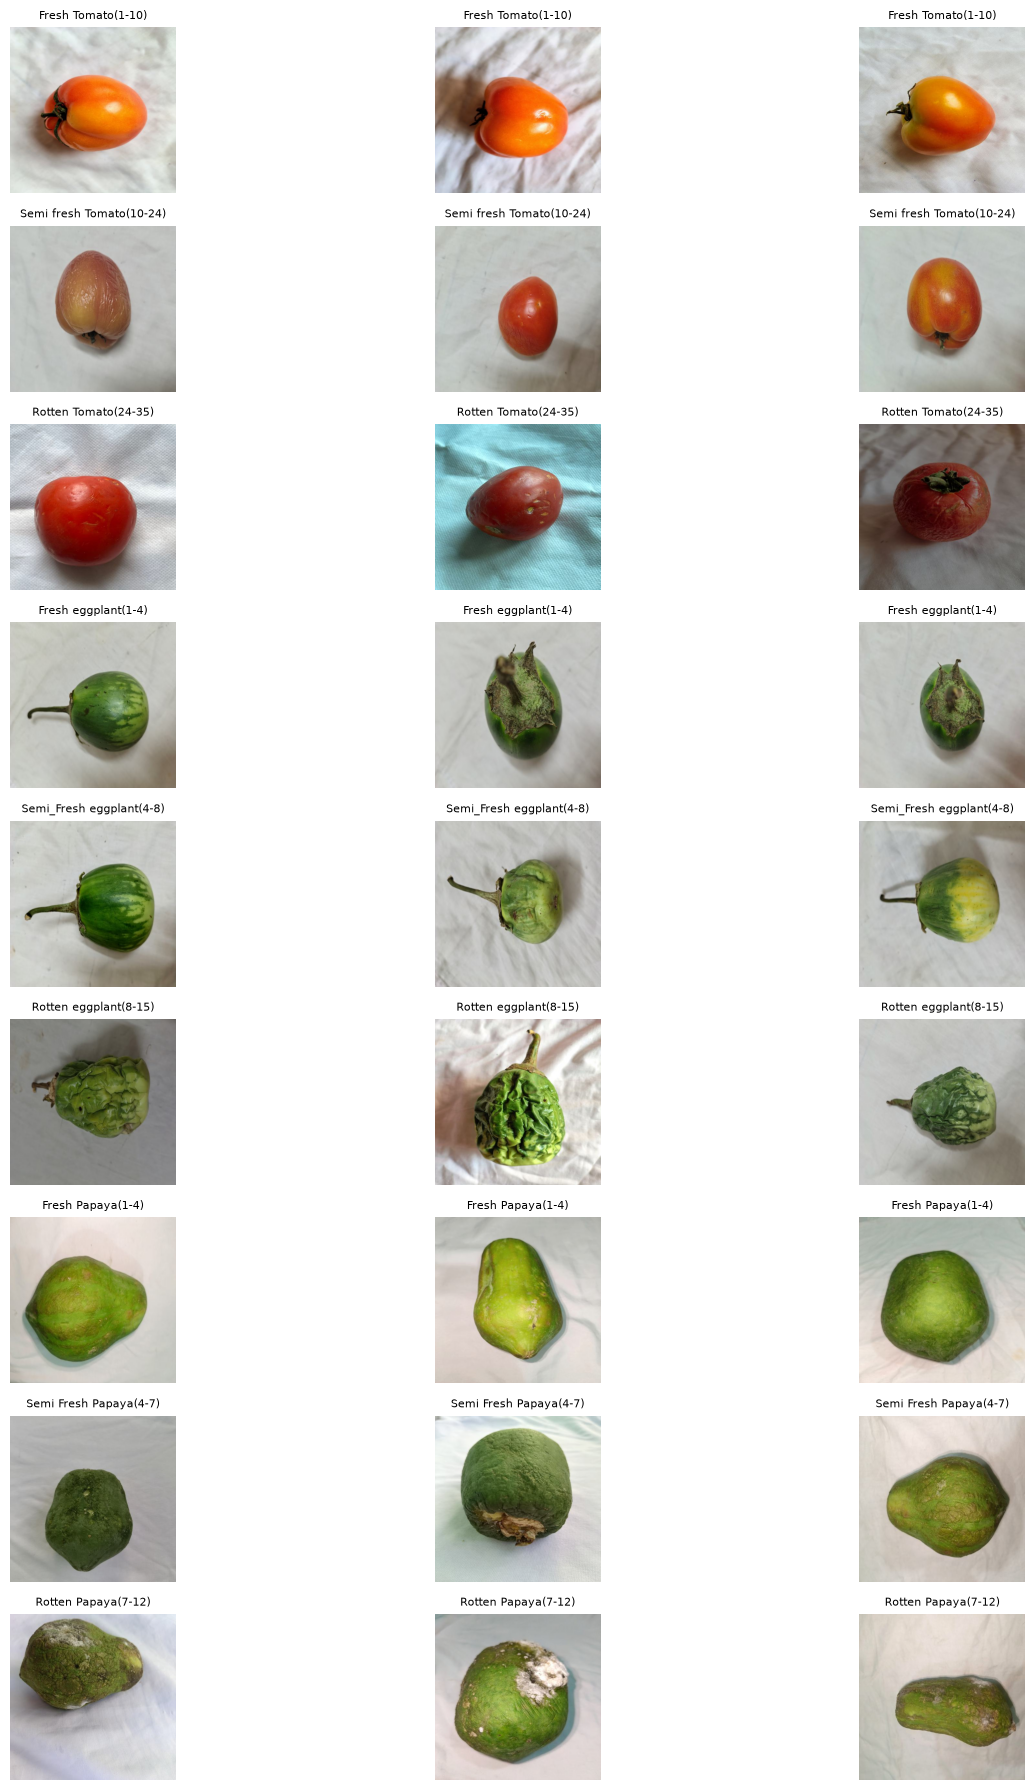

In [171]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

problem_classes = [
    "Fresh Tomato(1-10)",
    "Semi fresh Tomato(10-24)",
    "Rotten Tomato(24-35)",
    "Fresh eggplant(1-4)",
    "Semi_Fresh eggplant(4-8)",
    "Rotten eggplant(8-15)",
    "Fresh Papaya(1-4)",
    "Semi Fresh Papaya(4-7)",
    "Rotten Papaya(7-12)"
]

plt.figure(figsize=(15, 18))

plot_index = 1

for class_name in problem_classes:
    folder = os.path.join(dataset_path, class_name)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    samples = random.sample(images, min(3, len(images)))

    for image_name in samples:
        image = Image.open(
            os.path.join(folder, image_name)
        ).convert("RGB")

        plt.subplot(9, 3, plot_index)
        plt.imshow(image)
        plt.title(class_name, fontsize=8)
        plt.axis("off")

        plot_index += 1

plt.tight_layout()
plt.show()

In [4]:
import os
import hashlib
from collections import defaultdict

image_hashes = defaultdict(list)

for class_name in os.listdir(dataset_path):
    folder = os.path.join(dataset_path, class_name)

    if not os.path.isdir(folder):
        continue

    for filename in os.listdir(folder):
        filepath = os.path.join(folder, filename)

        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            with open(filepath, 'rb') as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            image_hashes[file_hash].append((class_name, filename))

duplicates = {
    h: files for h, files in image_hashes.items()
    if len(files) > 1
}

print("Total duplicate groups:", len(duplicates))

for files in list(duplicates.values())[:10]:
    print("\nDuplicate group:")
    for class_name, filename in files:
        print(class_name, "->", filename)

Total duplicate groups: 0


In [5]:
%pip install ImageHash

   ---------------------------------------- 0.0/4.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.3 MB ? eta -:--:--
   -- ------------------------------------- 0.3/4.3 MB ? eta -:--:--
   -- ------------------------------------- 0.3/4.3 MB ? eta -:--:--
   ---- ----------------------------------- 0.5/4.3 MB 530.0 kB/s eta 0:00:08
   ---- ----------------------------------- 0.5/4.3 MB 530.0 kB/s eta 0:00:08
   ---- ----------------------------------- 0.5/4.3 MB 530.0 kB/s eta 0:00:08
   ------- -------------------------------- 0.8/4.3 MB 526.5 kB/s eta 0:00:07
   ------- -------------------------------- 0.8/4.3 MB 526.5 kB/s eta 0:00:07
   ------------ --------------------------- 1.3/4.3 MB 678

In [11]:
import os
import imagehash
import numpy as np
from PIL import Image
from sklearn.neighbors import NearestNeighbors

hashes = []
image_paths = []

for class_name in os.listdir(dataset_path):
    folder = os.path.join(dataset_path, class_name)

    if not os.path.isdir(folder):
        continue

    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)

        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            try:
                img = Image.open(path).convert("RGB")
                h = imagehash.phash(img)

                hashes.append(
                    [int(bit) for bit in bin(int(str(h), 16))[2:].zfill(64)]
                )
                image_paths.append((class_name, filename))

            except Exception:
                continue

hash_array = np.array(hashes)

nn = NearestNeighbors(
    radius=4/64,
    metric='hamming',
    algorithm='brute',
    n_jobs=-1
)

nn.fit(hash_array)

near_duplicates = []

for start in range(0, len(hash_array), 256):
    end = min(start + 256, len(hash_array))

    distances, indices = nn.radius_neighbors(
        hash_array[start:end]
    )

    for i, (dists, neighbors) in enumerate(zip(distances, indices)):
        current = start + i

        for distance, neighbor in zip(dists, neighbors):
            if neighbor > current:
                near_duplicates.append(
                    (image_paths[current],
                     image_paths[neighbor],
                     round(distance * 64))
                )

print("Near-duplicate pairs:", len(near_duplicates))

for pair in near_duplicates[:15]:
    print(pair)

Near-duplicate pairs: 26059
(('Fresh Banana(1-4)', 'aug_0_IMG_20251104_131910090_HDR_AE~2.jpg'), ('Fresh Banana(1-4)', 'aug_100_IMG_20251104_131910090_HDR_AE~2.jpg'), 0)
(('Fresh Banana(1-4)', 'aug_0_IMG_20251104_131910090_HDR_AE~2.jpg'), ('Fresh Banana(1-4)', 'aug_222_IMG_20251104_131910090_HDR_AE~2.jpg'), 0)
(('Fresh Banana(1-4)', 'aug_0_IMG_20251104_131910090_HDR_AE~2.jpg'), ('Fresh Banana(1-4)', 'aug_337_IMG_20251104_131910090_HDR_AE~2.jpg'), 0)
(('Fresh Banana(1-4)', 'aug_0_IMG_20251104_131910090_HDR_AE~2.jpg'), ('Fresh Banana(1-4)', 'IMG_20251104_131910090_HDR_AE~2.jpg'), 0)
(('Fresh Banana(1-4)', 'aug_100_IMG_20251104_131910090_HDR_AE~2.jpg'), ('Fresh Banana(1-4)', 'aug_222_IMG_20251104_131910090_HDR_AE~2.jpg'), 0)
(('Fresh Banana(1-4)', 'aug_100_IMG_20251104_131910090_HDR_AE~2.jpg'), ('Fresh Banana(1-4)', 'aug_337_IMG_20251104_131910090_HDR_AE~2.jpg'), 0)
(('Fresh Banana(1-4)', 'aug_100_IMG_20251104_131910090_HDR_AE~2.jpg'), ('Fresh Banana(1-4)', 'IMG_20251104_131910090_HDR_AE~

In [12]:
import os

print("Dataset path:", dataset_path)
print("Path exists:", os.path.exists(dataset_path))

folders = os.listdir(dataset_path)

print("\nNumber of items:", len(folders))
print("\nFirst 10 items:")

for item in folders[:10]:
    path = os.path.join(dataset_path, item)

    if os.path.isdir(path):
        files = os.listdir(path)
        print(item, "->", len(files), "files")
        print("Sample filenames:", files[:3])

Dataset path: C:\Users\hp\Downloads\Processed Data\Processed Data
Path exists: True

Number of items: 24

First 10 items:
Fresh Banana(1-4) -> 590 files
Sample filenames: ['aug_0_IMG_20251104_131910090_HDR_AE~2.jpg', 'aug_100_IMG_20251104_131910090_HDR_AE~2.jpg', 'aug_101_IMG_20251119_201217560_HDR.jpg']
Fresh Bittermelon(1-3) -> 590 files
Sample filenames: ['aug_0_IMG_20260116_025957.jpg', 'aug_100_IMG_20251027_171156.jpg', 'aug_101_IMG_20251027_171204.jpg']
Fresh Cucumber(1-6) -> 590 files
Sample filenames: ['aug_0_IMG_20251025_121754.jpg', 'aug_100_IMG_20260114_010355.jpg', 'aug_101_IMG_20260116_030149.jpg']
Fresh eggplant(1-4) -> 590 files
Sample filenames: ['aug_0_IMG_20251118_164757182_HDR.jpg', 'aug_100_IMG_20251118_164855671_HDR.jpg', 'aug_101_IMG_20251106_160533486_HDR_AE.jpg']
Fresh Orange(1-9) -> 590 files
Sample filenames: ['aug_0_IMG_20251107_113920647_HDR_AE.jpg', 'aug_100_IMG_20251110_094248325_HDR_AE.jpg', 'aug_101_IMG-20251112-WA0015.jpg']
Fresh Papaya(1-4) -> 590 file

In [13]:
from collections import Counter

extensions = Counter()

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        extensions[os.path.splitext(file)[1].lower()] += 1

print(extensions)

Counter({'.jpg': 13890, '.jpeg': 270})


In [ ]:
total_images = 0

for root, dirs, files in os.walk(dataset_path):
    total_images += sum(
        f.lower().endswith(('.jpg', '.jpeg', '.png'))
        for f in files
    )

print("Total images:", total_images)

Total images: 14160


In [15]:
from collections import defaultdict

groups = defaultdict(list)

for (class_name, filename) in image_paths:
    original_name = filename

    if original_name.startswith("aug_"):
        original_name = original_name.split("_", 2)[-1]

    groups[(class_name, original_name)].append(filename)

print("Total images:", len(image_paths))
print("Unique original-name groups:", len(groups))

repeated_groups = {
    key: files for key, files in groups.items()
    if len(files) > 1
}

print("Groups with multiple versions:", len(repeated_groups))

print("\nExamples:")

for key, files in list(repeated_groups.items())[:10]:
    print(key, "->", len(files), "versions")

Total images: 14160
Unique original-name groups: 5217
Groups with multiple versions: 3526

Examples:
('Fresh Banana(1-4)', 'IMG_20251104_131910090_HDR_AE~2.jpg') -> 5 versions
('Fresh Banana(1-4)', 'IMG_20251119_201217560_HDR.jpg') -> 7 versions
('Fresh Banana(1-4)', 'IMG_20251102_081029133_AE.jpg') -> 5 versions
('Fresh Banana(1-4)', 'IMG_20251102_075754032_HDR_AE.jpg') -> 5 versions
('Fresh Banana(1-4)', 'IMG_20251102_075643318_HDR_AE.jpg') -> 2 versions
('Fresh Banana(1-4)', 'IMG_20251119_201452252_HDR.jpg') -> 4 versions
('Fresh Banana(1-4)', 'IMG_20251104_131828715_HDR_AE.jpg') -> 3 versions
('Fresh Banana(1-4)', 'IMG_20251103_192521600_HDR.jpg') -> 4 versions
('Fresh Banana(1-4)', 'IMG_20251102_075800601_HDR_AE.jpg') -> 2 versions
('Fresh Banana(1-4)', 'Banana (17).jpeg') -> 6 versions


In [25]:
print("Training has file paths:", hasattr(train_ds, "file_paths"))
print("Validation has file paths:", hasattr(val_ds, "file_paths"))
print("Testing has file paths:", hasattr(test_ds, "file_paths"))

Training has file paths: False
Validation has file paths: False
Testing has file paths: False


In [26]:
import os
import hashlib
from collections import defaultdict

image_hashes = defaultdict(list)

for class_name in os.listdir(dataset_path):
    folder = os.path.join(dataset_path, class_name)

    if not os.path.isdir(folder):
        continue

    for filename in os.listdir(folder):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            filepath = os.path.join(folder, filename)

            with open(filepath, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            image_hashes[file_hash].append(
                (class_name, filename)
            )

duplicate_groups = {
    h: files for h, files in image_hashes.items()
    if len(files) > 1
}

print("Total images scanned:", sum(map(len, image_hashes.values())))
print("Exact duplicate groups:", len(duplicate_groups))
print(
    "Images involved in duplicates:",
    sum(len(files) for files in duplicate_groups.values())
)

Total images scanned: 14160
Exact duplicate groups: 36
Images involved in duplicates: 76


In [27]:
cross_class_duplicates = {}

for file_hash, files in duplicate_groups.items():
    classes = set(class_name for class_name, filename in files)

    if len(classes) > 1:
        cross_class_duplicates[file_hash] = files

print("Duplicate groups across different classes:",
      len(cross_class_duplicates))

for files in list(cross_class_duplicates.values())[:10]:
    print("\n", files)

Duplicate groups across different classes: 17

 [('Fresh Orange(1-9)', 'IMG-20251122-WA0000.jpg'), ('Semi fresh Orange(9-20)', 'IMG-20251122-WA0000.jpg')]

 [('Fresh Orange(1-9)', 'IMG-20251122-WA0001.jpg'), ('Semi fresh Orange(9-20)', 'IMG-20251122-WA0001.jpg')]

 [('Fresh Orange(1-9)', 'IMG-20251122-WA0002.jpg'), ('Semi fresh Orange(9-20)', 'IMG-20251122-WA0002.jpg')]

 [('Fresh Orange(1-9)', 'IMG-20251122-WA0003.jpg'), ('Semi fresh Orange(9-20)', 'IMG-20251122-WA0003.jpg')]

 [('Fresh Orange(1-9)', 'IMG-20251122-WA0004.jpg'), ('Semi fresh Orange(9-20)', 'IMG-20251122-WA0004.jpg')]

 [('Fresh Orange(1-9)', 'IMG-20251122-WA0005.jpg'), ('Semi fresh Orange(9-20)', 'IMG-20251122-WA0005.jpg')]

 [('Fresh Orange(1-9)', 'IMG-20251122-WA0006.jpg'), ('Semi fresh Orange(9-20)', 'IMG-20251122-WA0006.jpg')]

 [('Fresh Orange(1-9)', 'IMG-20251122-WA0007.jpg'), ('Semi fresh Orange(9-20)', 'IMG-20251122-WA0007.jpg')]

 [('Fresh Orange(1-9)', 'IMG-20251122-WA0008.jpg'), ('Semi fresh Orange(9-20)', '

In [28]:
for files in cross_class_duplicates.values():
    print("\nDuplicate image:")
    for class_name, filename in files:
        print(f"  {class_name} -> {filename}")


Duplicate image:
  Fresh Orange(1-9) -> IMG-20251122-WA0000.jpg
  Semi fresh Orange(9-20) -> IMG-20251122-WA0000.jpg

Duplicate image:
  Fresh Orange(1-9) -> IMG-20251122-WA0001.jpg
  Semi fresh Orange(9-20) -> IMG-20251122-WA0001.jpg

Duplicate image:
  Fresh Orange(1-9) -> IMG-20251122-WA0002.jpg
  Semi fresh Orange(9-20) -> IMG-20251122-WA0002.jpg

Duplicate image:
  Fresh Orange(1-9) -> IMG-20251122-WA0003.jpg
  Semi fresh Orange(9-20) -> IMG-20251122-WA0003.jpg

Duplicate image:
  Fresh Orange(1-9) -> IMG-20251122-WA0004.jpg
  Semi fresh Orange(9-20) -> IMG-20251122-WA0004.jpg

Duplicate image:
  Fresh Orange(1-9) -> IMG-20251122-WA0005.jpg
  Semi fresh Orange(9-20) -> IMG-20251122-WA0005.jpg

Duplicate image:
  Fresh Orange(1-9) -> IMG-20251122-WA0006.jpg
  Semi fresh Orange(9-20) -> IMG-20251122-WA0006.jpg

Duplicate image:
  Fresh Orange(1-9) -> IMG-20251122-WA0007.jpg
  Semi fresh Orange(9-20) -> IMG-20251122-WA0007.jpg

Duplicate image:
  Fresh Orange(1-9) -> IMG-20251122-WA

In [29]:
excluded_paths = set()

for files in cross_class_duplicates.values():
    for class_name, filename in files:
        filepath = os.path.join(dataset_path, class_name, filename)
        excluded_paths.add(os.path.abspath(filepath))

print("Ambiguous files to exclude:", len(excluded_paths))

Ambiguous files to exclude: 34


In [30]:
from collections import defaultdict, Counter
import os
import hashlib

cleaned_records = []
seen_hashes = set()
removed_duplicates = 0

for class_name in sorted(os.listdir(dataset_path)):
    folder = os.path.join(dataset_path, class_name)

    if not os.path.isdir(folder):
        continue

    for filename in os.listdir(folder):
        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        filepath = os.path.abspath(os.path.join(folder, filename))

        if filepath in excluded_paths:
            continue

        with open(filepath, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        if file_hash in seen_hashes:
            removed_duplicates += 1
            continue

        seen_hashes.add(file_hash)

        original_name = filename

        if original_name.startswith("aug_"):
            original_name = original_name.split("_", 2)[-1]

        group_id = (class_name, original_name)

        cleaned_records.append({
            "path": filepath,
            "class_name": class_name,
            "group_id": group_id
        })

group_counts = defaultdict(int)

for record in cleaned_records:
    group_counts[record["group_id"]] += 1

print("Cleaned images:", len(cleaned_records))
print("Additional exact duplicates removed:", removed_duplicates)
print("Unique original-image groups:", len(group_counts))
print("Groups with multiple versions:",
      sum(1 for count in group_counts.values() if count > 1))
print("Classes:", len(set(r["class_name"] for r in cleaned_records)))

Cleaned images: 14103
Additional exact duplicates removed: 23
Unique original-image groups: 5203
Groups with multiple versions: 3508
Classes: 24


In [31]:
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

paths = np.array([r["path"] for r in cleaned_records])
labels = np.array([r["class_name"] for r in cleaned_records])

group_mapping = {
    group: i
    for i, group in enumerate(
        set(r["group_id"] for r in cleaned_records)
    )
}

groups = np.array([
    group_mapping[r["group_id"]]
    for r in cleaned_records
])

indices = np.arange(len(paths))

# First split: approximately 6/7 train+validation, 1/7 test
split1 = StratifiedGroupKFold(
    n_splits=7, shuffle=True, random_state=42
)

train_val_idx, test_idx = next(
    split1.split(indices, labels, groups)
)

# Second split: approximately 5/6 train, 1/6 validation
split2 = StratifiedGroupKFold(
    n_splits=6, shuffle=True, random_state=42
)

train_rel, val_rel = next(
    split2.split(
        train_val_idx,
        labels[train_val_idx],
        groups[train_val_idx]
    )
)

train_idx = train_val_idx[train_rel]
val_idx = train_val_idx[val_rel]

print("Training images:", len(train_idx))
print("Validation images:", len(val_idx))
print("Testing images:", len(test_idx))

print("\nGroup overlap checks:")
print("Train-Test:", len(set(groups[train_idx]) & set(groups[test_idx])))
print("Train-Val:", len(set(groups[train_idx]) & set(groups[val_idx])))
print("Val-Test:", len(set(groups[val_idx]) & set(groups[test_idx])))

print("\nClasses in each split:")
print("Train:", len(set(labels[train_idx])))
print("Validation:", len(set(labels[val_idx])))
print("Test:", len(set(labels[test_idx])))

Training images: 10073
Validation images: 2015
Testing images: 2015

Group overlap checks:
Train-Test: 0
Train-Val: 0
Val-Test: 0

Classes in each split:
Train: 24
Validation: 24
Test: 24


In [32]:
import pandas as pd

distribution = pd.DataFrame({
    "Training": pd.Series(labels[train_idx]).value_counts(),
    "Validation": pd.Series(labels[val_idx]).value_counts(),
    "Testing": pd.Series(labels[test_idx]).value_counts()
}).fillna(0).astype(int)

print(distribution.to_string())

                               Training  Validation  Testing
Fresh Banana(1-4)                   417          83       84
Fresh Bittermelon(1-3)              421          85       84
Fresh Cucumber(1-6)                 420          85       84
Fresh Orange(1-9)                   409          82       82
Fresh Papaya(1-4)                   419          84       84
Fresh Tomato(1-10)                  421          85       84
Fresh eggplant(1-4)                 421          84       85
Fresh pineapple(1-15)               421          84       85
Rotten Bittermelon(5-8)             421          84       84
Rotten Cucumber(12-20)              429          81       80
Rotten Orange(20-35)                420          85       83
Rotten Papaya(7-12)                 421          84       85
Rotten Pineapple(25-35)             421          85       84
Rotten Tomato(24-35)                421          84       85
Rotten banana(7-13)                 421          85       84
Rotten eggplant(8-15)   

In [33]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

class_names = sorted(set(labels))
class_to_index = {
    name: index for index, name in enumerate(class_names)
}

encoded_labels = np.array([
    class_to_index[label] for label in labels
])

def create_dataset(idx, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (paths[idx], encoded_labels[idx])
    )

    if shuffle:
        dataset = dataset.shuffle(
            len(idx), seed=42, reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = create_dataset(train_idx, shuffle=True)
val_ds = create_dataset(val_idx)
test_ds = create_dataset(test_idx)

In [34]:
for images, labels_batch in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels_batch.shape)
    print("Pixel range:", tf.reduce_min(images).numpy(),
          "to", tf.reduce_max(images).numpy())

Image shape: (32, 224, 224, 3)
Label shape: (32,)
Pixel range: 0.0 to 1.0


In [35]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    GlobalAveragePooling2D, Dense, Dropout
)

model = Sequential([
    Input(shape=(224, 224, 3)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(24, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,856 (440.84 KB)

 Trainable params: 112,856 (440.84 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        'best_food_model_grouped.keras',
        monitor='val_loss',
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=0.00001
    )
]

In [37]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20


c:\Users\hp\Food Spoilage Prediction\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


315/315 ━━━━━━━━━━━━━━━━━━━━ 457s 1s/step - accuracy: 0.1494 - loss: 2.7017 - val_accuracy: 0.3568 - val_loss: 2.0491 - learning_rate: 0.0010
Epoch 2/20
315/315 ━━━━━━━━━━━━━━━━━━━━ 1202s 4s/step - accuracy: 0.3357 - loss: 1.9535 - val_accuracy: 0.4149 - val_loss: 1.6594 - learning_rate: 0.0010
Epoch 3/20
315/315 ━━━━━━━━━━━━━━━━━━━━ 232s 735ms/step - accuracy: 0.4277 - loss: 1.6325 - val_accuracy: 0.5132 - val_loss: 1.4871 - learning_rate: 0.0010
Epoch 4/20
315/315 ━━━━━━━━━━━━━━━━━━━━ 246s 780ms/step - accuracy: 0.4886 - loss: 1.4454 - val_accuracy: 0.5618 - val_loss: 1.2228 - learning_rate: 0.0010
Epoch 5/20
315/315 ━━━━━━━━━━━━━━━━━━━━ 328s 1s/step - accuracy: 0.5313 - loss: 1.3084 - val_accuracy: 0.5474 - val_loss: 1.2369 - learning_rate: 0.0010
Epoch 6/20
315/315 ━━━━━━━━━━━━━━━━━━━━ 4117s 13s/step - accuracy: 0.5664 - loss: 1.1929 - val_accuracy: 0.6045 - val_loss: 1.1085 - learning_rate: 0.0010
Epoch 7/20
315/315 ━━━━━━━━━━━━━━━━━━━━ 245s 778ms/step - accuracy: 0.5808 - loss: 1

In [38]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 190ms/step - accuracy: 0.7965 - loss: 0.5471
Test Loss: 0.5471
Test Accuracy: 79.65 %


In [39]:
import numpy as np
from sklearn.metrics import classification_report

y_true = np.concatenate([
    y.numpy() for x, y in test_ds
])

y_prob = model.predict(test_ds)

y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=3,
    zero_division=0
))

63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 179ms/step
                               precision    recall  f1-score   support

            Fresh Banana(1-4)      0.864     0.905     0.884        84
       Fresh Bittermelon(1-3)      0.880     0.964     0.920        84
          Fresh Cucumber(1-6)      0.838     0.798     0.817        84
            Fresh Orange(1-9)      0.882     0.732     0.800        82
            Fresh Papaya(1-4)      0.730     0.774     0.751        84
           Fresh Tomato(1-10)      0.754     0.512     0.610        84
          Fresh eggplant(1-4)      0.574     0.776     0.660        85
        Fresh pineapple(1-15)      0.893     0.882     0.888        85
      Rotten Bittermelon(5-8)      0.737     0.833     0.782        84
       Rotten Cucumber(12-20)      0.959     0.887     0.922        80
         Rotten Orange(20-35)      0.927     0.916     0.921        83
          Rotten Papaya(7-12)      0.694     0.882     0.777        85
      Rotten Pineapple(25-35)     

In [40]:
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(24)
)

confusions = []

for i in range(24):
    for j in range(24):
        if i != j and cm[i, j] > 0:
            confusions.append((
                class_names[i],
                class_names[j],
                cm[i, j]
            ))

confusions.sort(key=lambda x: x[2], reverse=True)

print("Top 15 classification errors:\n")

for actual, predicted, count in confusions[:15]:
    print(f"{actual} -> {predicted}: {count}")

Top 15 classification errors:

Fresh Tomato(1-10) -> Semi fresh Tomato(10-24): 38
Semi_Fresh eggplant(4-8) -> Fresh eggplant(1-4): 30
Semi Fresh Papaya(4-7) -> Rotten Papaya(7-12): 26
Semi Fresh Papaya(4-7) -> Fresh Papaya(1-4): 18
Fresh eggplant(1-4) -> Semi_Fresh eggplant(4-8): 16
Semi Fresh Bittermelon ( 3-5) -> Rotten Bittermelon(5-8): 15
Fresh Papaya(1-4) -> Semi Fresh Papaya(4-7): 14
Rotten Bittermelon(5-8) -> Semi Fresh Bittermelon ( 3-5): 13
Rotten eggplant(8-15) -> Fresh eggplant(1-4): 13
Semi fresh Tomato(10-24) -> Rotten Tomato(24-35): 13
Semi fresh Tomato(10-24) -> Fresh Tomato(1-10): 12
Fresh Orange(1-9) -> Semi Fresh Cucumber(6-12): 11
Semi Fresh Papaya(4-7) -> Fresh Cucumber(1-6): 11
Rotten eggplant(8-15) -> Semi_Fresh eggplant(4-8): 10
Semi Fresh Bittermelon ( 3-5) -> Fresh Bittermelon(1-3): 10


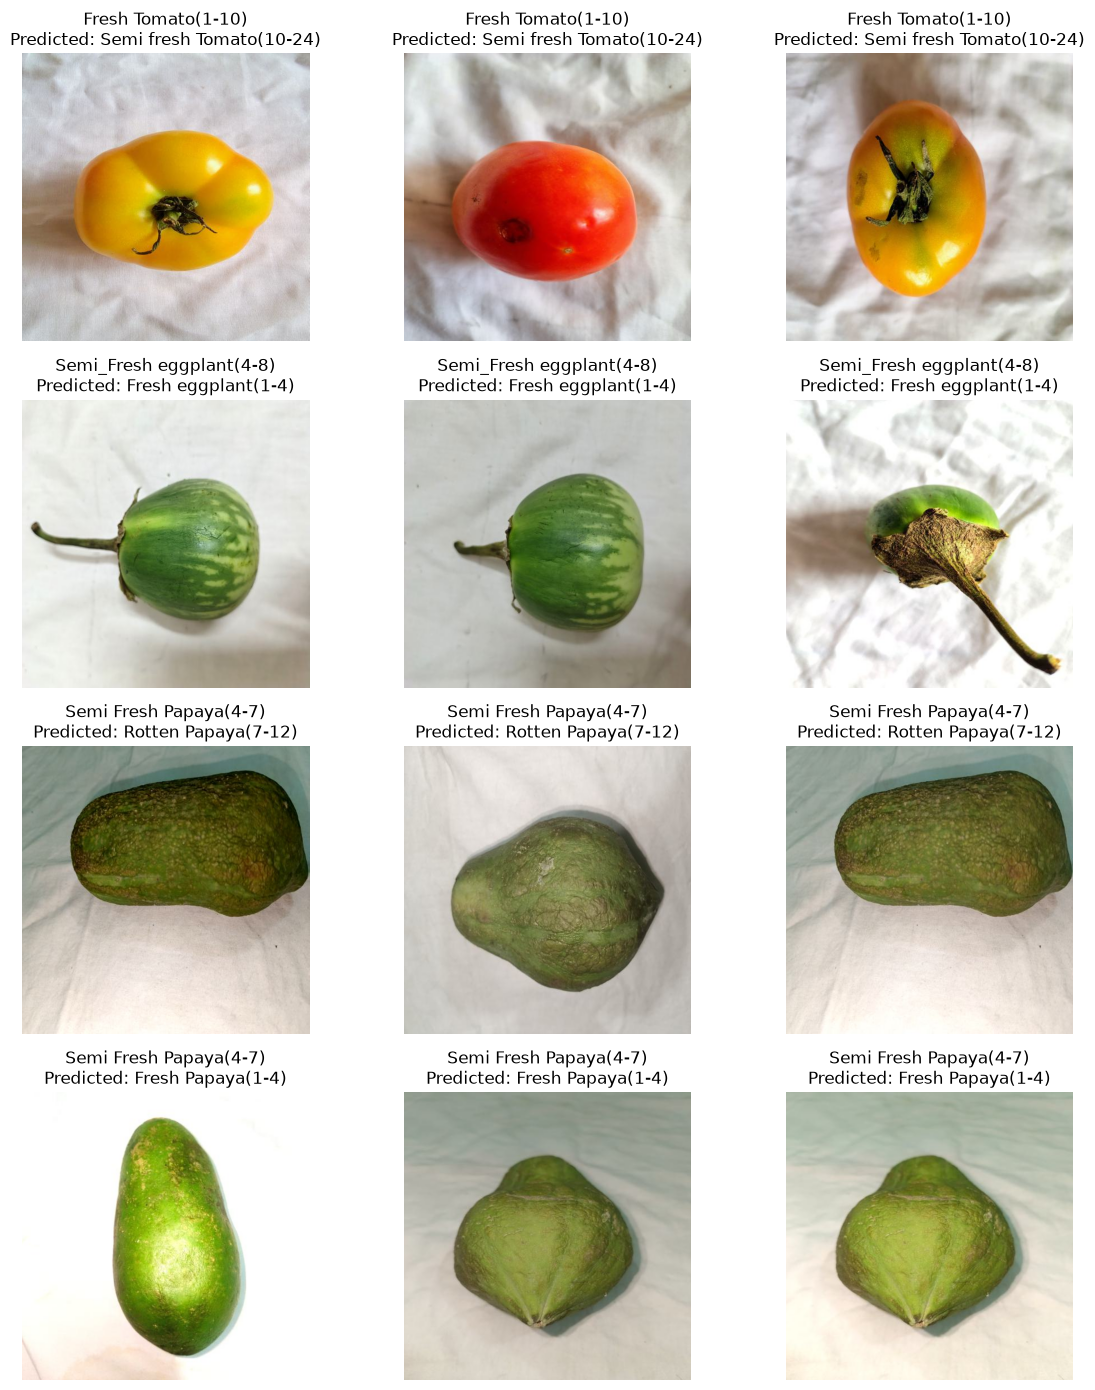

In [41]:
import matplotlib.pyplot as plt
import numpy as np

pairs = [
    ("Fresh Tomato(1-10)", "Semi fresh Tomato(10-24)"),
    ("Semi_Fresh eggplant(4-8)", "Fresh eggplant(1-4)"),
    ("Semi Fresh Papaya(4-7)", "Rotten Papaya(7-12)"),
    ("Semi Fresh Papaya(4-7)", "Fresh Papaya(1-4)")
]

test_paths = paths[test_idx]

fig, axes = plt.subplots(4, 3, figsize=(12, 14))

for row, (actual, predicted) in enumerate(pairs):

    actual_idx = class_to_index[actual]
    predicted_idx = class_to_index[predicted]

    error_indices = np.where(
        (y_true == actual_idx) &
        (y_pred == predicted_idx)
    )[0][:3]

    for col in range(3):
        ax = axes[row, col]

        if col < len(error_indices):
            idx = error_indices[col]

            img = plt.imread(test_paths[idx])
            ax.imshow(img)
            ax.set_title(f"{actual}\nPredicted: {predicted}")

        ax.axis("off")

plt.tight_layout()
plt.show()

In [42]:
import os

pairs_to_check = [
    ("Semi Fresh Papaya(4-7)", "Rotten Papaya(7-12)"),
    ("Semi Fresh Papaya(4-7)", "Fresh Papaya(1-4)")
]

test_paths = paths[test_idx]

for actual, predicted in pairs_to_check:

    actual_idx = class_to_index[actual]
    predicted_idx = class_to_index[predicted]

    error_indices = np.where(
        (y_true == actual_idx) &
        (y_pred == predicted_idx)
    )[0][:3]

    print(f"\n{actual} -> {predicted}")

    for idx in error_indices:
        print(os.path.basename(test_paths[idx]))


Semi Fresh Papaya(4-7) -> Rotten Papaya(7-12)
aug_115_IMG_20260120_004620.jpg
aug_124_IMG_20260120_004500.jpg
aug_128_IMG_20260120_004620.jpg

Semi Fresh Papaya(4-7) -> Fresh Papaya(1-4)
aug_114_IMG_20260214_025210.jpg
aug_186_IMG_20260125_005122.jpg
aug_207_IMG_20260125_005122.jpg


In [43]:
suspects = [
    "IMG_20260120_004620.jpg",
    "IMG_20260120_004500.jpg",
    "IMG_20260214_025210.jpg",
    "IMG_20260125_005122.jpg"
]

split_lookup = {}

for i in train_idx:
    split_lookup[paths[i]] = "Train"

for i in val_idx:
    split_lookup[paths[i]] = "Validation"

for i in test_idx:
    split_lookup[paths[i]] = "Test"

for original in suspects:

    print(f"\nOriginal: {original}")

    for record in cleaned_records:

        filename = os.path.basename(record["path"])

        base_name = filename
        if base_name.startswith("aug_"):
            base_name = base_name.split("_", 2)[-1]

        if base_name == original:
            print(
                record["class_name"],
                "|",
                filename,
                "|",
                split_lookup.get(record["path"], "Unknown")
            )


Original: IMG_20260120_004620.jpg
Semi Fresh Papaya(4-7) | aug_115_IMG_20260120_004620.jpg | Test
Semi Fresh Papaya(4-7) | aug_128_IMG_20260120_004620.jpg | Test
Semi Fresh Papaya(4-7) | aug_17_IMG_20260120_004620.jpg | Test
Semi Fresh Papaya(4-7) | aug_239_IMG_20260120_004620.jpg | Test
Semi Fresh Papaya(4-7) | aug_271_IMG_20260120_004620.jpg | Test
Semi Fresh Papaya(4-7) | aug_272_IMG_20260120_004620.jpg | Test
Semi Fresh Papaya(4-7) | aug_304_IMG_20260120_004620.jpg | Test
Semi Fresh Papaya(4-7) | aug_38_IMG_20260120_004620.jpg | Test
Semi Fresh Papaya(4-7) | aug_39_IMG_20260120_004620.jpg | Test
Semi Fresh Papaya(4-7) | aug_3_IMG_20260120_004620.jpg | Test
Semi Fresh Papaya(4-7) | aug_403_IMG_20260120_004620.jpg | Test
Semi Fresh Papaya(4-7) | aug_476_IMG_20260120_004620.jpg | Test
Semi Fresh Papaya(4-7) | aug_501_IMG_20260120_004620.jpg | Test
Semi Fresh Papaya(4-7) | aug_508_IMG_20260120_004620.jpg | Test
Semi Fresh Papaya(4-7) | IMG_20260120_004620.jpg | Test

Original: IMG_202

In [44]:
test_original_idx = []

seen_groups = set()

for i in test_idx:

    group = cleaned_records[i]["group_id"]

    if group not in seen_groups:

        test_original_idx.append(i)
        seen_groups.add(group)

print("Original test images:", len(test_original_idx))
print("Total test images:", len(test_idx))

test_original_ds = create_dataset(
    np.array(test_original_idx)
)

original_loss, original_accuracy = model.evaluate(
    test_original_ds
)

print(f"\nOriginal-only Test Accuracy: {original_accuracy * 100:.2f}%")

Original test images: 745
Total test images: 2015
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 162ms/step - accuracy: 0.7839 - loss: 0.5605

Original-only Test Accuracy: 78.39%


In [45]:
test_groups = {}

for i in test_idx:
    record = cleaned_records[i]
    group = record["group_id"]
    filename = os.path.basename(record["path"])

    if group not in test_groups:
        test_groups[group] = i

    if not filename.startswith("aug_"):
        test_groups[group] = i

original_test_idx = np.array(list(test_groups.values()))

original_test_ds = create_dataset(original_test_idx)

loss, accuracy = model.evaluate(original_test_ds)

print("Original photographs:", len(original_test_idx))
print(f"Original-only Test Accuracy: {accuracy * 100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 164ms/step - accuracy: 0.8107 - loss: 0.4738
Original photographs: 745
Original-only Test Accuracy: 81.07%


In [46]:
from sklearn.metrics import classification_report
import numpy as np

y_true_original = np.concatenate([
    y.numpy() for x, y in original_test_ds
])

y_prob_original = model.predict(original_test_ds)

y_pred_original = np.argmax(y_prob_original, axis=1)

print(classification_report(
    y_true_original,
    y_pred_original,
    target_names=class_names,
    digits=3,
    zero_division=0
))

24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 163ms/step
                               precision    recall  f1-score   support

            Fresh Banana(1-4)      0.893     0.962     0.926        26
       Fresh Bittermelon(1-3)      0.931     0.964     0.947        28
          Fresh Cucumber(1-6)      0.944     0.850     0.895        20
            Fresh Orange(1-9)      0.871     0.750     0.806        36
            Fresh Papaya(1-4)      0.737     0.824     0.778        17
           Fresh Tomato(1-10)      0.843     0.512     0.637        84
          Fresh eggplant(1-4)      0.595     0.735     0.658        34
        Fresh pineapple(1-15)      0.938     0.938     0.938        32
      Rotten Bittermelon(5-8)      0.931     0.871     0.900        31
       Rotten Cucumber(12-20)      0.857     1.000     0.923         6
         Rotten Orange(20-35)      0.941     1.000     0.970        16
          Rotten Papaya(7-12)      0.958     0.958     0.958        48
      Rotten Pineapple(25-35)      

In [47]:
from collections import Counter

class_group_counts = Counter(
    record["class_name"]
    for record in cleaned_records
    if not os.path.basename(record["path"]).startswith("aug_")
)

for class_name in class_names:
    print(f"{class_name}: {class_group_counts[class_name]}")

Fresh Banana(1-4): 173
Fresh Bittermelon(1-3): 196
Fresh Cucumber(1-6): 139
Fresh Orange(1-9): 238
Fresh Papaya(1-4): 115
Fresh Tomato(1-10): 590
Fresh eggplant(1-4): 236
Fresh pineapple(1-15): 220
Rotten Bittermelon(5-8): 213
Rotten Cucumber(12-20): 47
Rotten Orange(20-35): 114
Rotten Papaya(7-12): 332
Rotten Pineapple(25-35): 212
Rotten Tomato(24-35): 248
Rotten banana(7-13): 301
Rotten eggplant(8-15): 153
Semi Fresh Bittermelon ( 3-5): 109
Semi Fresh Cucumber(6-12): 223
Semi Fresh Papaya(4-7): 49
Semi fresh Orange(9-20): 395
Semi fresh Pineapple (15-25): 119
Semi fresh Tomato(10-24): 290
Semi fresh banana(4-7): 195
Semi_Fresh eggplant(4-8): 254


In [48]:
import tensorflow as tf

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

from tensorflow.keras.models import Model

In [49]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Total layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 22s 2us/step
MobileNetV2 loaded successfully!
Total layers: 154


In [50]:
inputs = Input(shape=(224, 224, 3))

x = preprocess_input(inputs * 255.0)

x = base_model(x, training=False)

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation='relu')(x)

x = Dropout(0.4)(x)

outputs = Dense(24, activation='softmax')(x)

mobilenet_model = Model(inputs, outputs)

In [51]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

mobilenet_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │         6,168 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,592,088 (9.89 MB)

 Trainable params: 334,104 (1.27 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [52]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

mobilenet_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        'best_mobilenet_food.keras',
        monitor='val_loss',
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=0.00001
    )
]

In [53]:
mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=mobilenet_callbacks
)

Epoch 1/15


c:\Users\hp\Food Spoilage Prediction\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


315/315 ━━━━━━━━━━━━━━━━━━━━ 290s 876ms/step - accuracy: 0.8012 - loss: 0.5890 - val_accuracy: 0.8700 - val_loss: 0.3292 - learning_rate: 0.0010
Epoch 2/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 265s 842ms/step - accuracy: 0.9204 - loss: 0.2163 - val_accuracy: 0.8799 - val_loss: 0.3236 - learning_rate: 0.0010
Epoch 3/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 254s 805ms/step - accuracy: 0.9490 - loss: 0.1412 - val_accuracy: 0.8958 - val_loss: 0.2639 - learning_rate: 0.0010
Epoch 4/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 230s 729ms/step - accuracy: 0.9647 - loss: 0.1006 - val_accuracy: 0.9017 - val_loss: 0.2349 - learning_rate: 0.0010
Epoch 5/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 353s 1s/step - accuracy: 0.9703 - loss: 0.0849 - val_accuracy: 0.8968 - val_loss: 0.3180 - learning_rate: 0.0010
Epoch 6/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 479s 2s/step - accuracy: 0.9757 - loss: 0.0706 - val_accuracy: 0.9007 - val_loss: 0.2830 - learning_rate: 0.0010
Epoch 7/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 267s 847ms/step - accuracy: 0.9882 - loss

In [54]:
mobilenet_loss, mobilenet_accuracy = mobilenet_model.evaluate(
    original_test_ds
)

print(f"MobileNetV2 Test Accuracy: {mobilenet_accuracy*100:.2f}%")
print(f"Test Loss: {mobilenet_loss:.4f}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 635ms/step - accuracy: 0.9181 - loss: 0.2111
MobileNetV2 Test Accuracy: 91.81%
Test Loss: 0.2111


In [55]:
y_prob_mobilenet = mobilenet_model.predict(original_test_ds)

y_pred_mobilenet = np.argmax(y_prob_mobilenet, axis=1)

print(classification_report(
    y_true_original,
    y_pred_mobilenet,
    target_names=class_names,
    digits=3,
    zero_division=0
))

24/24 ━━━━━━━━━━━━━━━━━━━━ 19s 747ms/step
                               precision    recall  f1-score   support

            Fresh Banana(1-4)      0.962     0.962     0.962        26
       Fresh Bittermelon(1-3)      0.966     1.000     0.982        28
          Fresh Cucumber(1-6)      1.000     0.950     0.974        20
            Fresh Orange(1-9)      0.971     0.917     0.943        36
            Fresh Papaya(1-4)      0.941     0.941     0.941        17
           Fresh Tomato(1-10)      0.936     0.869     0.901        84
          Fresh eggplant(1-4)      0.750     0.794     0.771        34
        Fresh pineapple(1-15)      0.970     1.000     0.985        32
      Rotten Bittermelon(5-8)      0.939     1.000     0.969        31
       Rotten Cucumber(12-20)      0.857     1.000     0.923         6
         Rotten Orange(20-35)      1.000     0.938     0.968        16
          Rotten Papaya(7-12)      0.959     0.979     0.969        48
      Rotten Pineapple(25-35)     

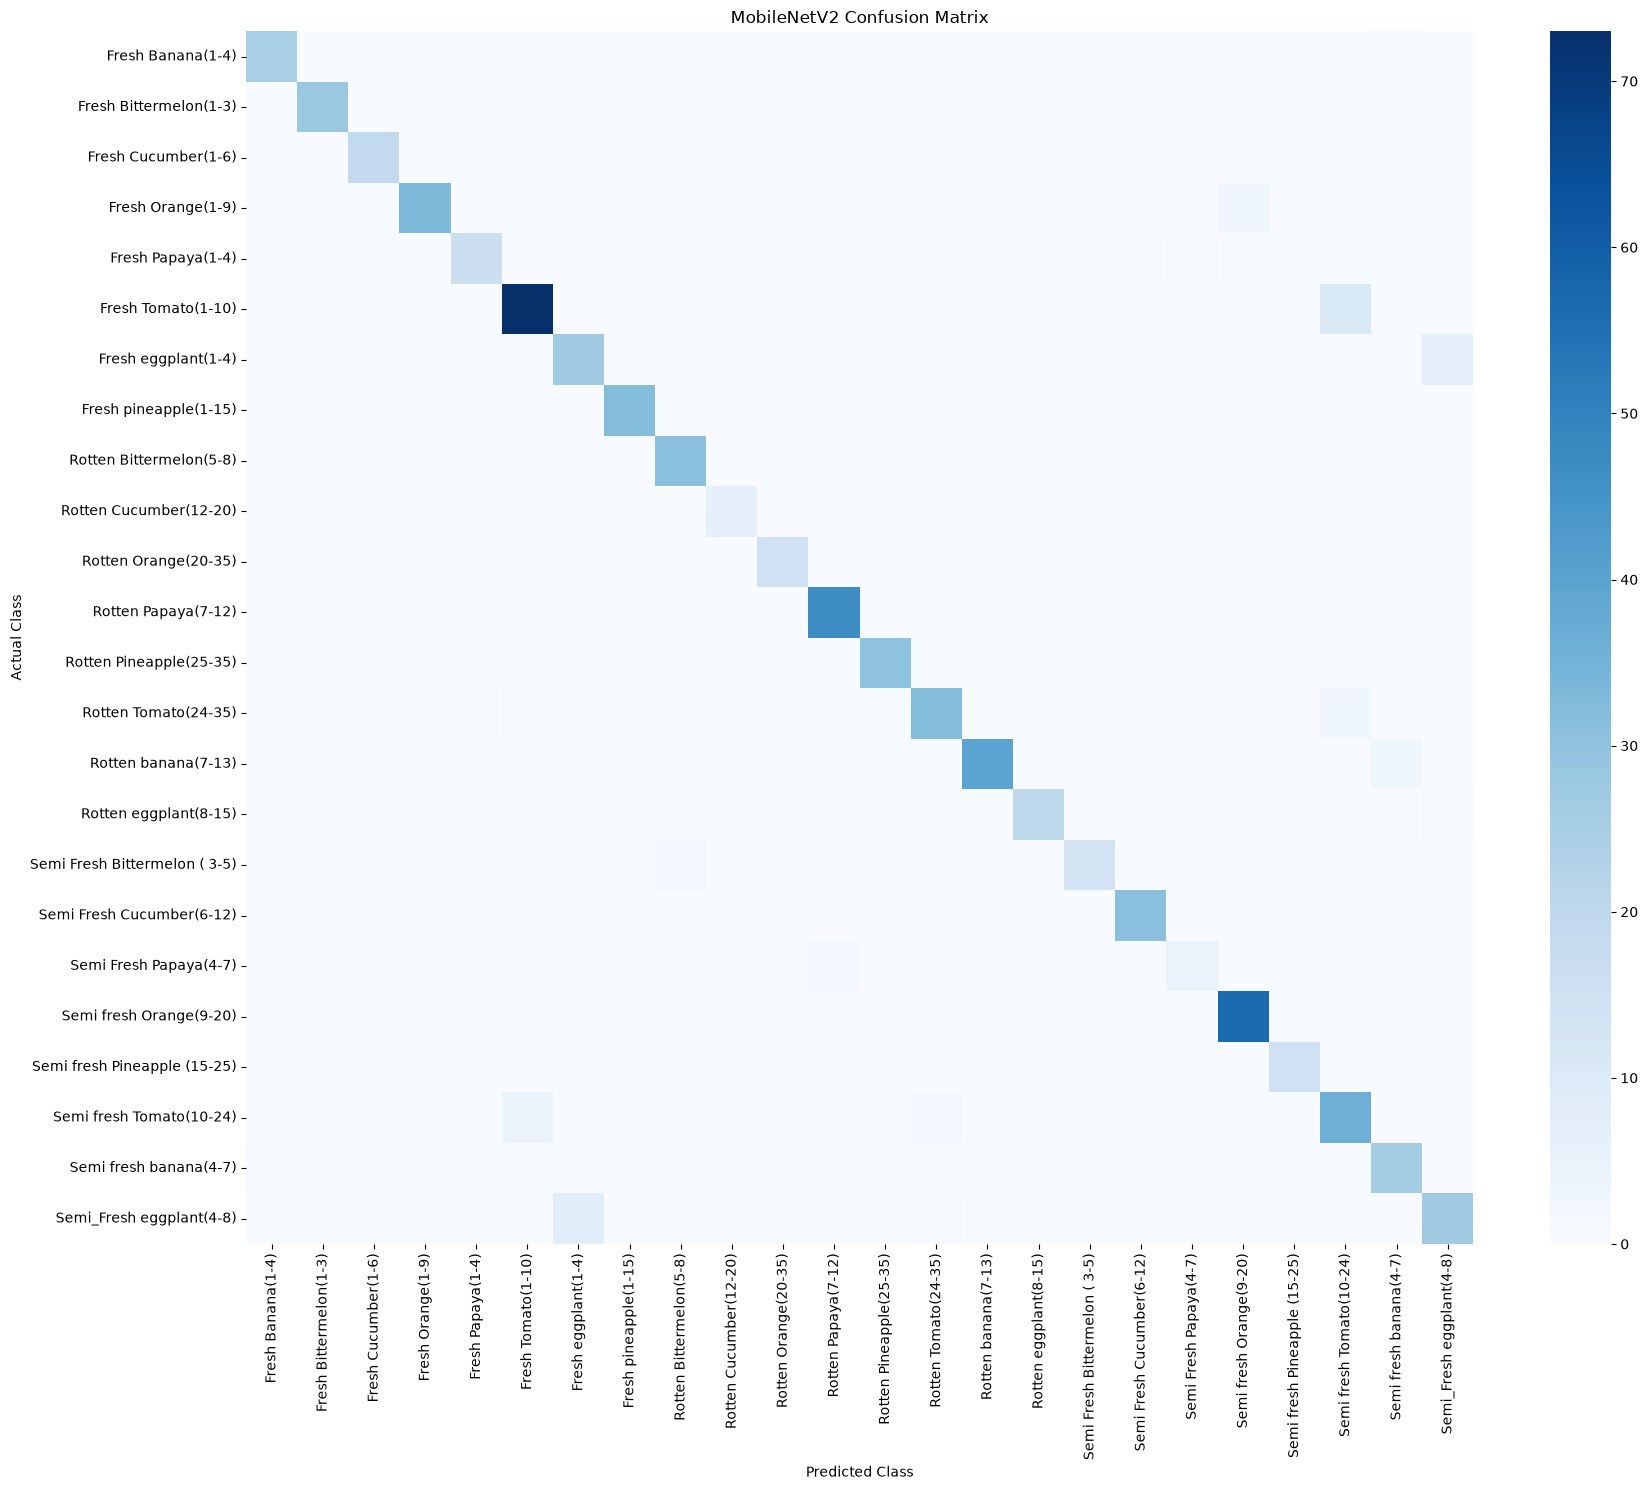

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true_original,
    y_pred_mobilenet
)

plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("MobileNetV2 Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [57]:
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(y_true_original, y_pred_mobilenet)

errors = []

for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm[i, j] > 0:
            errors.append((
                class_names[i],
                class_names[j],
                cm[i, j]
            ))

errors.sort(key=lambda x: x[2], reverse=True)

print("Top 15 classification errors:\n")

for actual, predicted, count in errors[:15]:
    print(f"{actual} -> {predicted}: {count}")

Top 15 classification errors:

Fresh Tomato(1-10) -> Semi fresh Tomato(10-24): 11
Semi_Fresh eggplant(4-8) -> Fresh eggplant(1-4): 8
Fresh eggplant(1-4) -> Semi_Fresh eggplant(4-8): 7
Semi fresh Tomato(10-24) -> Fresh Tomato(1-10): 4
Fresh Orange(1-9) -> Semi fresh Orange(9-20): 3
Rotten Tomato(24-35) -> Semi fresh Tomato(10-24): 3
Rotten banana(7-13) -> Semi fresh banana(4-7): 3
Semi Fresh Bittermelon ( 3-5) -> Rotten Bittermelon(5-8): 2
Semi Fresh Papaya(4-7) -> Rotten Papaya(7-12): 2
Semi fresh Tomato(10-24) -> Rotten Tomato(24-35): 2
Fresh Banana(1-4) -> Semi fresh banana(4-7): 1
Fresh Cucumber(1-6) -> Semi Fresh Cucumber(6-12): 1
Fresh Papaya(1-4) -> Semi Fresh Papaya(4-7): 1
Rotten Orange(20-35) -> Semi fresh Orange(9-20): 1
Rotten Papaya(7-12) -> Fresh Papaya(1-4): 1


In [58]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

In [59]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [60]:
print("Trainable parameters:",
      sum(tf.keras.backend.count_params(w)
          for w in mobilenet_model.trainable_weights))

Trainable parameters: 1844824


In [61]:
fine_tune_callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        'best_mobilenet_finetuned.keras',
        monitor='val_loss',
        save_best_only=True
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=0.000001
    )
]

fine_tune_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=fine_tune_callbacks
)

Epoch 1/10


c:\Users\hp\Food Spoilage Prediction\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


315/315 ━━━━━━━━━━━━━━━━━━━━ 386s 1s/step - accuracy: 0.9780 - loss: 0.0652 - val_accuracy: 0.9156 - val_loss: 0.2546 - learning_rate: 1.0000e-05
Epoch 2/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 331s 1s/step - accuracy: 0.9878 - loss: 0.0421 - val_accuracy: 0.9002 - val_loss: 0.2930 - learning_rate: 1.0000e-05
Epoch 3/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 517s 2s/step - accuracy: 0.9900 - loss: 0.0334 - val_accuracy: 0.9072 - val_loss: 0.2521 - learning_rate: 1.0000e-05
Epoch 4/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 1880s 6s/step - accuracy: 0.9935 - loss: 0.0234 - val_accuracy: 0.9251 - val_loss: 0.2406 - learning_rate: 1.0000e-05
Epoch 5/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 302s 960ms/step - accuracy: 0.9946 - loss: 0.0208 - val_accuracy: 0.9161 - val_loss: 0.2669 - learning_rate: 1.0000e-05
Epoch 6/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 290s 921ms/step - accuracy: 0.9949 - loss: 0.0169 - val_accuracy: 0.9231 - val_loss: 0.2558 - learning_rate: 1.0000e-05
Epoch 7/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 335s 1s/step - accurac

In [62]:
fine_loss, fine_accuracy = mobilenet_model.evaluate(
    original_test_ds
)

print(f"Fine-tuned Test Accuracy: {fine_accuracy*100:.2f}%")
print(f"Fine-tuned Test Loss: {fine_loss:.4f}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 16s 680ms/step - accuracy: 0.9450 - loss: 0.1886
Fine-tuned Test Accuracy: 94.50%
Fine-tuned Test Loss: 0.1886


In [63]:
y_prob_finetuned = mobilenet_model.predict(original_test_ds)

y_pred_finetuned = np.argmax(y_prob_finetuned, axis=1)

print(classification_report(
    y_true_original,
    y_pred_finetuned,
    target_names=class_names,
    digits=3,
    zero_division=0
))

24/24 ━━━━━━━━━━━━━━━━━━━━ 16s 644ms/step
                               precision    recall  f1-score   support

            Fresh Banana(1-4)      0.962     0.962     0.962        26
       Fresh Bittermelon(1-3)      0.966     1.000     0.982        28
          Fresh Cucumber(1-6)      1.000     0.950     0.974        20
            Fresh Orange(1-9)      0.972     0.972     0.972        36
            Fresh Papaya(1-4)      1.000     0.941     0.970        17
           Fresh Tomato(1-10)      0.963     0.940     0.952        84
          Fresh eggplant(1-4)      0.844     0.794     0.818        34
        Fresh pineapple(1-15)      1.000     0.969     0.984        32
      Rotten Bittermelon(5-8)      0.939     1.000     0.969        31
       Rotten Cucumber(12-20)      0.750     1.000     0.857         6
         Rotten Orange(20-35)      1.000     1.000     1.000        16
          Rotten Papaya(7-12)      0.960     1.000     0.980        48
      Rotten Pineapple(25-35)     

In [64]:
import imagehash
from PIL import Image
import os

split_indices = {
    "Train": train_idx,
    "Validation": val_idx,
    "Test": test_idx
}

hashes = {}

for split, indices in split_indices.items():
    for i in indices:
        image_path = cleaned_records[i]["path"]

        with Image.open(image_path) as img:
            phash = imagehash.phash(img)

        hashes[i] = int(str(phash), 16)

print("Perceptual hashes calculated:", len(hashes))

Perceptual hashes calculated: 14103


In [65]:
import numpy as np

bit_count = np.array([bin(i).count("1") for i in range(256)])

split_hashes = {}

for split, indices in split_indices.items():
    split_hashes[split] = np.array(
        [hashes[i] for i in indices], dtype=np.uint64
    )

def check_near_duplicates(a, b, threshold=4):
    a = a.astype(np.uint64)
    b = b.astype(np.uint64)

    matches = []

    for start in range(0, len(a), 128):
        chunk = a[start:start+128]

        xor = chunk[:, None] ^ b[None, :]

        bytes_array = xor.view(np.uint8).reshape(
            len(chunk), len(b), 8
        )

        distances = bit_count[bytes_array].sum(axis=2)

        rows, cols = np.where(distances <= threshold)

        for r, c in zip(rows, cols):
            matches.append((start + r, c, int(distances[r, c])))

    return matches

for first, second in [
    ("Train", "Validation"),
    ("Train", "Test"),
    ("Validation", "Test")
]:
    matches = check_near_duplicates(
        split_hashes[first],
        split_hashes[second]
    )

    print(f"{first} vs {second}: {len(matches)} near-duplicate pairs")

Train vs Validation: 918 near-duplicate pairs
Train vs Test: 640 near-duplicate pairs
Validation vs Test: 133 near-duplicate pairs


In [66]:
match_results = {}

for first, second in [
    ("Train", "Validation"),
    ("Train", "Test"),
    ("Validation", "Test")
]:
    match_results[(first, second)] = check_near_duplicates(
        split_hashes[first],
        split_hashes[second]
    )

for (first, second), matches in match_results.items():
    print(f"\n{first} vs {second}")

    for a, b, distance in matches[:10]:
        i = split_indices[first][a]
        j = split_indices[second][b]

        r1 = cleaned_records[i]
        r2 = cleaned_records[j]

        print(
            f"Distance: {distance} | "
            f"{os.path.basename(r1['path'])} | "
            f"{os.path.basename(r2['path'])} | "
            f"{r1['class_name']} | {r2['class_name']}"
        )


Train vs Validation
Distance: 0 | aug_170_IMG_20251104_131713223_HDR_AE~6.jpg | aug_143_IMG_20251104_131713223_HDR_AE~5.jpg | Fresh Banana(1-4) | Fresh Banana(1-4)
Distance: 0 | aug_170_IMG_20251104_131713223_HDR_AE~6.jpg | aug_146_IMG_20251104_131713223_HDR_AE~3.jpg | Fresh Banana(1-4) | Fresh Banana(1-4)
Distance: 0 | aug_170_IMG_20251104_131713223_HDR_AE~6.jpg | aug_373_IMG_20251104_131713223_HDR_AE~3.jpg | Fresh Banana(1-4) | Fresh Banana(1-4)
Distance: 0 | aug_245_IMG_20251104_131713223_HDR_AE~6.jpg | aug_143_IMG_20251104_131713223_HDR_AE~5.jpg | Fresh Banana(1-4) | Fresh Banana(1-4)
Distance: 0 | aug_245_IMG_20251104_131713223_HDR_AE~6.jpg | aug_146_IMG_20251104_131713223_HDR_AE~3.jpg | Fresh Banana(1-4) | Fresh Banana(1-4)
Distance: 0 | aug_245_IMG_20251104_131713223_HDR_AE~6.jpg | aug_373_IMG_20251104_131713223_HDR_AE~3.jpg | Fresh Banana(1-4) | Fresh Banana(1-4)
Distance: 0 | aug_305_IMG_20251104_131713223_HDR_AE~6.jpg | aug_143_IMG_20251104_131713223_HDR_AE~5.jpg | Fresh Ban

In [68]:
new_groups = [
    (
        record["class_name"],
        get_original_group(record["path"])
    )
    for record in cleaned_records
]

print("Total images:", len(new_groups))
print("Unique improved groups:", len(set(new_groups)))

Total images: 14103
Unique improved groups: 5195


In [69]:
train_groups = {new_groups[i] for i in train_idx}
val_groups = {new_groups[i] for i in val_idx}
test_groups = {new_groups[i] for i in test_idx}

print("Train-Val overlap:", len(train_groups & val_groups))
print("Train-Test overlap:", len(train_groups & test_groups))
print("Val-Test overlap:", len(val_groups & test_groups))

Train-Val overlap: 2
Train-Test overlap: 1
Val-Test overlap: 1


In [70]:
overlaps = [
    ("Train-Val", train_groups & val_groups, train_idx, val_idx),
    ("Train-Test", train_groups & test_groups, train_idx, test_idx),
    ("Val-Test", val_groups & test_groups, val_idx, test_idx)
]

for name, common, idx1, idx2 in overlaps:
    print(f"\n{name}")

    for group in common:
        print("\nGroup:", group)

        for i in idx1:
            if new_groups[i] == group:
                print("Split 1:", cleaned_records[i]["path"])

        for i in idx2:
            if new_groups[i] == group:
                print("Split 2:", cleaned_records[i]["path"])


Train-Val

Group: ('Fresh Banana(1-4)', 'IMG_20251104_131700306_HDR_AE.jpg')
Split 1: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Banana(1-4)\aug_256_IMG_20251104_131700306_HDR_AE.jpg
Split 1: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Banana(1-4)\aug_325_IMG_20251104_131700306_HDR_AE.jpg
Split 1: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Banana(1-4)\aug_344_IMG_20251104_131700306_HDR_AE~4.jpg
Split 1: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Banana(1-4)\aug_346_IMG_20251104_131700306_HDR_AE.jpg
Split 1: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Banana(1-4)\aug_47_IMG_20251104_131700306_HDR_AE.jpg
Split 1: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Banana(1-4)\aug_61_IMG_20251104_131700306_HDR_AE.jpg
Split 1: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Banana(1-4)\IMG_20251104_131700306_HDR_AE.jpg
Split 2: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Banana(1-4)\aug_

In [71]:
from sklearn.model_selection import StratifiedGroupKFold

paths = np.array([r["path"] for r in cleaned_records])
labels = np.array([r["class_name"] for r in cleaned_records])

group_mapping = {
    group: i
    for i, group in enumerate(set(new_groups))
}

groups = np.array([
    group_mapping[group] for group in new_groups
])

indices = np.arange(len(paths))

split1 = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=42
)

train_val_idx, test_idx = next(
    split1.split(indices, labels, groups)
)

split2 = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)

train_rel, val_rel = next(
    split2.split(
        train_val_idx,
        labels[train_val_idx],
        groups[train_val_idx]
    )
)

train_idx = train_val_idx[train_rel]
val_idx = train_val_idx[val_rel]

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

Training: 10074
Validation: 2014
Testing: 2015


In [72]:
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

print("Train-Val:", len(train_groups & val_groups))
print("Train-Test:", len(train_groups & test_groups))
print("Val-Test:", len(val_groups & test_groups))

Train-Val: 0
Train-Test: 0
Val-Test: 0


In [73]:
encoded_labels = np.array([
    class_to_index[label] for label in labels
])

train_ds = create_dataset(train_idx, shuffle=True)
val_ds = create_dataset(val_idx)
test_ds = create_dataset(test_idx)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

Training batches: 315
Validation batches: 63
Testing batches: 63


In [74]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = Input(shape=(224, 224, 3))

x = preprocess_input(inputs * 255.0)
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.4)(x)

outputs = Dense(24, activation="softmax")(x)

mobilenet_model = Model(inputs, outputs)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply_1 (Multiply)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 24)             │         6,168 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,592,088 (9.89 MB)

 Trainable params: 334,104 (1.27 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [75]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_mobilenet_food.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6
    )
]

history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15


c:\Users\hp\Food Spoilage Prediction\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


315/315 ━━━━━━━━━━━━━━━━━━━━ 414s 1s/step - accuracy: 0.8031 - loss: 0.5864 - val_accuracy: 0.8853 - val_loss: 0.3000 - learning_rate: 0.0010
Epoch 2/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 452s 1s/step - accuracy: 0.9223 - loss: 0.2085 - val_accuracy: 0.9022 - val_loss: 0.2640 - learning_rate: 0.0010
Epoch 3/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 339s 1s/step - accuracy: 0.9504 - loss: 0.1397 - val_accuracy: 0.9161 - val_loss: 0.2298 - learning_rate: 0.0010
Epoch 4/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 331s 1s/step - accuracy: 0.9616 - loss: 0.1067 - val_accuracy: 0.9215 - val_loss: 0.2467 - learning_rate: 0.0010
Epoch 5/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 306s 971ms/step - accuracy: 0.9691 - loss: 0.0869 - val_accuracy: 0.9295 - val_loss: 0.2337 - learning_rate: 0.0010
Epoch 6/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 357s 1s/step - accuracy: 0.9853 - loss: 0.0464 - val_accuracy: 0.9335 - val_loss: 0.2066 - learning_rate: 2.0000e-04
Epoch 7/15
315/315 ━━━━━━━━━━━━━━━━━━━━ 420s 1s/step - accuracy: 0.9907 - loss: 0.0351

In [76]:
test_loss, test_accuracy = mobilenet_model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

63/63 ━━━━━━━━━━━━━━━━━━━━ 44s 695ms/step - accuracy: 0.9216 - loss: 0.2262
Test Loss: 0.2262
Test Accuracy: 92.16%


In [77]:
import os
import numpy as np

test_groups_dict = {}

for i in test_idx:
    group = new_groups[i]
    filename = os.path.basename(cleaned_records[i]["path"])

    if group not in test_groups_dict:
        test_groups_dict[group] = i

    if not filename.startswith("aug_"):
        test_groups_dict[group] = i

original_test_idx = np.array(list(test_groups_dict.values()))

original_test_ds = create_dataset(original_test_idx)

print("Original test images:", len(original_test_idx))
print("Original test batches:", len(original_test_ds))

Original test images: 743
Original test batches: 24


In [78]:
original_loss, original_accuracy = mobilenet_model.evaluate(
    original_test_ds
)

print(f"Original Test Loss: {original_loss:.4f}")
print(f"Original Test Accuracy: {original_accuracy * 100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 608ms/step - accuracy: 0.9314 - loss: 0.2052
Original Test Loss: 0.2052
Original Test Accuracy: 93.14%


In [79]:
from sklearn.metrics import classification_report

y_true = np.concatenate([
    y.numpy() for _, y in original_test_ds
])

y_prob = mobilenet_model.predict(original_test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0,
    digits=3
))

24/24 ━━━━━━━━━━━━━━━━━━━━ 17s 636ms/step
                               precision    recall  f1-score   support

            Fresh Banana(1-4)      0.920     0.920     0.920        25
       Fresh Bittermelon(1-3)      1.000     1.000     1.000        28
          Fresh Cucumber(1-6)      0.955     1.000     0.977        21
            Fresh Orange(1-9)      0.923     1.000     0.960        36
            Fresh Papaya(1-4)      0.944     1.000     0.971        17
           Fresh Tomato(1-10)      0.987     0.917     0.951        84
          Fresh eggplant(1-4)      0.857     0.727     0.787        33
        Fresh pineapple(1-15)      0.969     0.969     0.969        32
      Rotten Bittermelon(5-8)      1.000     0.774     0.873        31
       Rotten Cucumber(12-20)      1.000     1.000     1.000         6
         Rotten Orange(20-35)      1.000     1.000     1.000        16
          Rotten Papaya(7-12)      0.979     1.000     0.989        47
      Rotten Pineapple(25-35)     

In [80]:
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(y_true, y_pred)

errors = []

for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm[i, j] > 0:
            errors.append((
                class_names[i],
                class_names[j],
                cm[i, j]
            ))

errors.sort(key=lambda x: x[2], reverse=True)

print("Top 10 classification errors:\n")

for actual, predicted, count in errors[:10]:
    print(f"{actual} -> {predicted}: {count}")

Top 10 classification errors:

Fresh eggplant(1-4) -> Semi_Fresh eggplant(4-8): 9
Fresh Tomato(1-10) -> Semi fresh Tomato(10-24): 7
Rotten Bittermelon(5-8) -> Semi Fresh Bittermelon ( 3-5): 7
Rotten Tomato(24-35) -> Semi fresh Tomato(10-24): 4
Semi_Fresh eggplant(4-8) -> Fresh eggplant(1-4): 4
Semi fresh Orange(9-20) -> Fresh Orange(1-9): 3
Fresh Banana(1-4) -> Semi fresh banana(4-7): 2
Semi fresh banana(4-7) -> Fresh Banana(1-4): 2
Semi fresh banana(4-7) -> Rotten banana(7-13): 2
Semi_Fresh eggplant(4-8) -> Rotten eggplant(8-15): 2


In [81]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))

print("Trainable parameters:", sum(
    np.prod(v.shape) for v in mobilenet_model.trainable_weights
))

Trainable layers: 19
Trainable parameters: 1844824


In [82]:
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [83]:
fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_mobilenet_finetuned.keras",
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

fine_tune_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=fine_tune_callbacks
)

Epoch 1/10


c:\Users\hp\Food Spoilage Prediction\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


315/315 ━━━━━━━━━━━━━━━━━━━━ 320s 1s/step - accuracy: 0.9867 - loss: 0.0400 - val_accuracy: 0.9355 - val_loss: 0.2363 - learning_rate: 1.0000e-05
Epoch 2/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 297s 941ms/step - accuracy: 0.9923 - loss: 0.0263 - val_accuracy: 0.9374 - val_loss: 0.2341 - learning_rate: 1.0000e-05
Epoch 3/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 840s 3s/step - accuracy: 0.9953 - loss: 0.0182 - val_accuracy: 0.9340 - val_loss: 0.2376 - learning_rate: 1.0000e-05
Epoch 4/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 286s 909ms/step - accuracy: 0.9953 - loss: 0.0170 - val_accuracy: 0.9305 - val_loss: 0.2540 - learning_rate: 1.0000e-05
Epoch 5/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 345s 1s/step - accuracy: 0.9985 - loss: 0.0091 - val_accuracy: 0.9364 - val_loss: 0.2310 - learning_rate: 2.0000e-06
Epoch 6/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 278s 881ms/step - accuracy: 0.9988 - loss: 0.0083 - val_accuracy: 0.9419 - val_loss: 0.2334 - learning_rate: 2.0000e-06
Epoch 7/10
315/315 ━━━━━━━━━━━━━━━━━━━━ 262s 833ms/step - ac

In [84]:
original_loss_ft, original_accuracy_ft = mobilenet_model.evaluate(
    original_test_ds
)

print(f"Fine-tuned Test Loss: {original_loss_ft:.4f}")
print(f"Fine-tuned Test Accuracy: {original_accuracy_ft * 100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 17s 701ms/step - accuracy: 0.9502 - loss: 0.1853
Fine-tuned Test Loss: 0.1853
Fine-tuned Test Accuracy: 95.02%


In [85]:
y_prob_ft = mobilenet_model.predict(original_test_ds)
y_pred_ft = np.argmax(y_prob_ft, axis=1)

print(classification_report(
    y_true,
    y_pred_ft,
    target_names=class_names,
    zero_division=0,
    digits=3
))

24/24 ━━━━━━━━━━━━━━━━━━━━ 18s 718ms/step
                               precision    recall  f1-score   support

            Fresh Banana(1-4)      0.957     0.880     0.917        25
       Fresh Bittermelon(1-3)      1.000     1.000     1.000        28
          Fresh Cucumber(1-6)      1.000     1.000     1.000        21
            Fresh Orange(1-9)      0.946     0.972     0.959        36
            Fresh Papaya(1-4)      0.944     1.000     0.971        17
           Fresh Tomato(1-10)      0.988     0.964     0.976        84
          Fresh eggplant(1-4)      0.900     0.818     0.857        33
        Fresh pineapple(1-15)      0.970     1.000     0.985        32
      Rotten Bittermelon(5-8)      1.000     0.774     0.873        31
       Rotten Cucumber(12-20)      1.000     1.000     1.000         6
         Rotten Orange(20-35)      1.000     1.000     1.000        16
          Rotten Papaya(7-12)      0.979     1.000     0.989        47
      Rotten Pineapple(25-35)     

In [86]:
mobilenet_model.save("food_spoilage_mobilenetv2.keras")

In [87]:
saved_model = tf.keras.models.load_model(
    "food_spoilage_mobilenetv2.keras"
)

images, labels = next(iter(original_test_ds))

original_predictions = mobilenet_model.predict(images)
saved_predictions = saved_model.predict(images)

difference = np.max(
    np.abs(original_predictions - saved_predictions)
)

print("Maximum prediction difference:", difference)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Maximum prediction difference: 0.0


In [88]:
[name for name in globals() if "hash" in name.lower()]

['hashlib',
 'image_hashes',
 'imagehash',
 'hashes',
 'hash_array',
 'file_hash',
 'seen_hashes',
 'phash',
 'split_hashes']

In [89]:
for name in [
    "image_hashes",
    "hashes",
    "hash_array",
    "phash",
    "split_hashes"
]:
    obj = globals().get(name)
    if obj is not None:
        print(
            name,
            "| Type:", type(obj),
            "| Length:", len(obj) if hasattr(obj, "__len__") else "N/A"
        )

image_hashes | Type: <class 'collections.defaultdict'> | Length: 14120
hashes | Type: <class 'dict'> | Length: 14103
hash_array | Type: <class 'numpy.ndarray'> | Length: 14160
phash | Type: <class 'imagehash.ImageHash'> | Length: 64
split_hashes | Type: <class 'dict'> | Length: 3


In [90]:
print("Hash entries:", len(hashes))
print("Cleaned images:", len(cleaned_records))

print("\nSample hash entry:")
key = next(iter(hashes))
print("Path:", key)
print("Hash:", hashes[key])

Hash entries: 14103
Cleaned images: 14103

Sample hash entry:
Path: 0
Hash: 13606183810604307665


In [91]:
print("First 5 entries:", list(hashes.items())[:5])
print("Last 5 keys:", list(hashes.keys())[-5:])

print(
    "Keys match dataset indices:",
    set(hashes.keys()) == set(range(len(cleaned_records)))
)

First 5 entries: [(np.int64(0), 13606183810604307665), (np.int64(1), 13606183810604307665), (np.int64(2), 17116161551999497435), (np.int64(4), 13748576010129105763), (np.int64(8), 17116372552011835798)]
Last 5 keys: [np.int64(14084), np.int64(14087), np.int64(14095), np.int64(14101), np.int64(14102)]
Keys match dataset indices: True


In [92]:
import numpy as np

hash_values = np.array(
    [hashes[i] for i in range(len(cleaned_records))],
    dtype=np.uint64
)

def find_near_duplicates(idx_a, idx_b, threshold=4):
    matches = []
    hash_b = hash_values[idx_b]

    for start in range(0, len(idx_a), 128):
        chunk_idx = idx_a[start:start + 128]

        xor = np.bitwise_xor(
            hash_values[chunk_idx, None],
            hash_b[None, :]
        )

        distances = np.unpackbits(
            xor.view(np.uint8).reshape(
                len(chunk_idx), len(idx_b), 8
            ),
            axis=2
        ).sum(axis=2)

        rows, cols = np.where(distances <= threshold)

        for r, c in zip(rows, cols):
            matches.append((
                chunk_idx[r],
                idx_b[c],
                distances[r, c]
            ))

    return matches


train_val = find_near_duplicates(train_idx, val_idx)
train_test = find_near_duplicates(train_idx, test_idx)
val_test = find_near_duplicates(val_idx, test_idx)

print("Near-duplicate pairs (distance <= 4):")
print("Train-Val:", len(train_val))
print("Train-Test:", len(train_test))
print("Val-Test:", len(val_test))

Near-duplicate pairs (distance <= 4):
Train-Val: 550
Train-Test: 796
Val-Test: 120


In [93]:
def inspect_matches(matches, title, limit=10):
    print(f"\n{title}")
    print("-" * 100)

    for i, j, distance in matches[:limit]:
        print(
            f"Distance: {distance} | "
            f"Class A: {cleaned_records[i]['class_name']} | "
            f"Class B: {cleaned_records[j]['class_name']}"
        )

        print("Image A:", os.path.basename(cleaned_records[i]["path"]))
        print("Image B:", os.path.basename(cleaned_records[j]["path"]))
        print("Same original group:", new_groups[i] == new_groups[j])
        print()


inspect_matches(train_val, "TRAIN - VALIDATION")
inspect_matches(train_test, "TRAIN - TEST")
inspect_matches(val_test, "VALIDATION - TEST")


TRAIN - VALIDATION
----------------------------------------------------------------------------------------------------
Distance: 4 | Class A: Fresh Banana(1-4) | Class B: Fresh Banana(1-4)
Image A: IMG_20251119_201149589_HDR.jpg
Image B: aug_375_IMG_20251120_203124771_HDR.jpg
Same original group: False

Distance: 4 | Class A: Fresh Banana(1-4) | Class B: Fresh Banana(1-4)
Image A: IMG_20251119_201149589_HDR.jpg
Image B: IMG_20251120_203124771_HDR.jpg
Same original group: False

Distance: 4 | Class A: Fresh Banana(1-4) | Class B: Fresh Banana(1-4)
Image A: IMG_20251119_201444954_HDR.jpg
Image B: aug_235_IMG_20251119_201401592_HDR.jpg
Same original group: False

Distance: 4 | Class A: Fresh Banana(1-4) | Class B: Fresh Banana(1-4)
Image A: IMG_20251119_201444954_HDR.jpg
Image B: aug_244_IMG_20251119_201401592_HDR.jpg
Same original group: False

Distance: 4 | Class A: Fresh Banana(1-4) | Class B: Fresh Banana(1-4)
Image A: IMG_20251119_201444954_HDR.jpg
Image B: aug_370_IMG_20251119_201

In [94]:
def count_distances(matches):
    return {
        d: sum(1 for _, _, dist in matches if dist == d)
        for d in range(5)
    }

print("Train-Val:", count_distances(train_val))
print("Train-Test:", count_distances(train_test))
print("Val-Test:", count_distances(val_test))

Train-Val: {0: 15, 1: 0, 2: 117, 3: 0, 4: 418}
Train-Test: {0: 25, 1: 0, 2: 97, 3: 0, 4: 674}
Val-Test: {0: 2, 1: 0, 2: 27, 3: 0, 4: 91}


In [95]:
def inspect_exact_phash_matches(matches, title):
    print(f"\n{title}")
    print("-" * 80)

    exact = [m for m in matches if m[2] == 0]

    for i, j, distance in exact:
        print("Class A:", cleaned_records[i]["class_name"])
        print("Class B:", cleaned_records[j]["class_name"])

        print("Image A:", cleaned_records[i]["path"])
        print("Image B:", cleaned_records[j]["path"])

        print("Same original group:", new_groups[i] == new_groups[j])
        print()


inspect_exact_phash_matches(train_val, "TRAIN-VALIDATION")
inspect_exact_phash_matches(train_test, "TRAIN-TEST")
inspect_exact_phash_matches(val_test, "VALIDATION-TEST")


TRAIN-VALIDATION
--------------------------------------------------------------------------------
Class A: Fresh Tomato(1-10)
Class B: Fresh Tomato(1-10)
Image A: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Tomato(1-10)\IMG_20251120_203936572_HDR.jpg
Image B: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Tomato(1-10)\IMG_20251120_203809335_HDR.jpg
Same original group: False

Class A: Fresh eggplant(1-4)
Class B: Fresh eggplant(1-4)
Image A: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh eggplant(1-4)\aug_239_IMG_20251122_205637558_HDR.jpg
Image B: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh eggplant(1-4)\aug_196_IMG_20251122_205632444_HDR.jpg
Same original group: False

Class A: Fresh eggplant(1-4)
Class B: Fresh eggplant(1-4)
Image A: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh eggplant(1-4)\aug_239_IMG_20251122_205637558_HDR.jpg
Image B: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh eggplant(1-4)\aug_272_IM

In [96]:
def cross_class_exact_matches(matches):
    results = []

    for i, j, distance in matches:
        if distance == 0:
            class_a = cleaned_records[i]["class_name"]
            class_b = cleaned_records[j]["class_name"]

            if class_a != class_b:
                results.append((
                    i, j, class_a, class_b
                ))

    return results


for name, match_list in [
    ("Train-Val", train_val),
    ("Train-Test", train_test),
    ("Val-Test", val_test)
]:
    results = cross_class_exact_matches(match_list)

    print(f"\n{name}: {len(results)} cross-class matches")

    for i, j, class_a, class_b in results:
        print(
            os.path.basename(cleaned_records[i]["path"]),
            "|",
            class_a,
            "<->",
            os.path.basename(cleaned_records[j]["path"]),
            "|",
            class_b
        )


Train-Val: 4 cross-class matches
aug_31_IMG-20251122-WA0000.jpg | Semi fresh Orange(9-20) <-> aug_173_IMG-20251122-WA0000.jpg | Fresh Orange(1-9)
aug_31_IMG-20251122-WA0000.jpg | Semi fresh Orange(9-20) <-> aug_251_IMG-20251122-WA0000.jpg | Fresh Orange(1-9)
aug_57_IMG_20251116_220609831_HDR.jpg | Semi fresh Orange(9-20) <-> aug_115_IMG_20251116_220609831_HDR.jpg | Fresh Orange(1-9)
aug_57_IMG_20251116_220609831_HDR.jpg | Semi fresh Orange(9-20) <-> aug_9_IMG_20251116_220609831_HDR.jpg | Fresh Orange(1-9)

Train-Test: 4 cross-class matches
aug_149_IMG-20251122-WA0009.jpg | Fresh Orange(1-9) <-> aug_76_IMG-20251122-WA0009.jpg | Semi fresh Orange(9-20)
IMG_20251125_211626878_HDR.jpg | Fresh Tomato(1-10) <-> aug_213_IMG_20251125_211221870_HDR.jpg | Semi fresh Tomato(10-24)
IMG_20251125_211626878_HDR.jpg | Fresh Tomato(1-10) <-> IMG_20251125_211221870_HDR.jpg | Semi fresh Tomato(10-24)
aug_120_IMG-20251122-WA0007.jpg | Semi fresh Orange(9-20) <-> aug_139_IMG-20251122-WA0007.jpg | Fresh Or

In [97]:
import hashlib
import os

def get_md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()


checked = set()

for matches in [train_val, train_test, val_test]:
    for i, j, distance in matches:
        if distance != 0:
            continue

        class_a = cleaned_records[i]["class_name"]
        class_b = cleaned_records[j]["class_name"]

        if class_a == class_b:
            continue

        pair = tuple(sorted((i, j)))

        if pair in checked:
            continue

        checked.add(pair)

        path_a = cleaned_records[i]["path"]
        path_b = cleaned_records[j]["path"]

        print("\n", os.path.basename(path_a))
        print("Class A:", class_a)
        print("Class B:", class_b)
        print("Identical MD5:", get_md5(path_a) == get_md5(path_b))


 aug_31_IMG-20251122-WA0000.jpg
Class A: Semi fresh Orange(9-20)
Class B: Fresh Orange(1-9)
Identical MD5: False

 aug_31_IMG-20251122-WA0000.jpg
Class A: Semi fresh Orange(9-20)
Class B: Fresh Orange(1-9)
Identical MD5: False

 aug_57_IMG_20251116_220609831_HDR.jpg
Class A: Semi fresh Orange(9-20)
Class B: Fresh Orange(1-9)
Identical MD5: False

 aug_57_IMG_20251116_220609831_HDR.jpg
Class A: Semi fresh Orange(9-20)
Class B: Fresh Orange(1-9)
Identical MD5: False

 aug_149_IMG-20251122-WA0009.jpg
Class A: Fresh Orange(1-9)
Class B: Semi fresh Orange(9-20)
Identical MD5: False

 IMG_20251125_211626878_HDR.jpg
Class A: Fresh Tomato(1-10)
Class B: Semi fresh Tomato(10-24)
Identical MD5: False

 IMG_20251125_211626878_HDR.jpg
Class A: Fresh Tomato(1-10)
Class B: Semi fresh Tomato(10-24)
Identical MD5: False

 aug_120_IMG-20251122-WA0007.jpg
Class A: Semi fresh Orange(9-20)
Class B: Fresh Orange(1-9)
Identical MD5: False


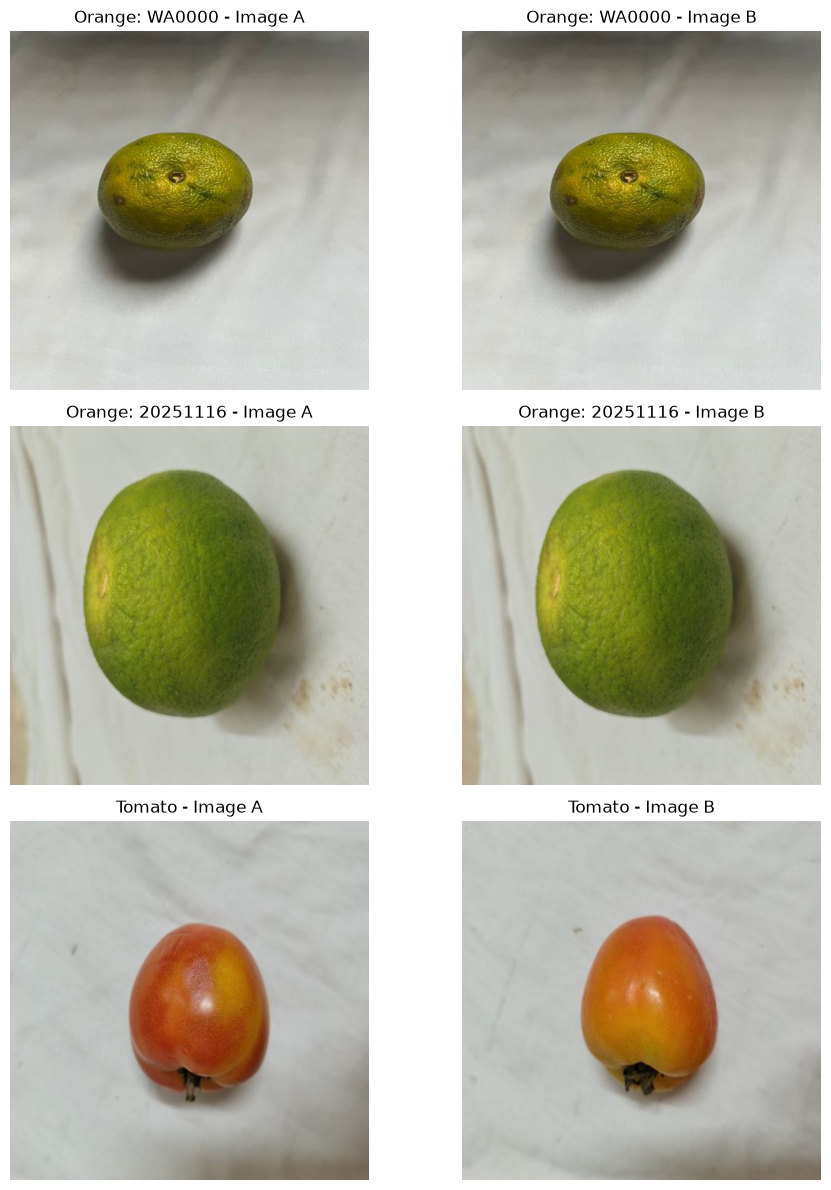

In [98]:
import matplotlib.pyplot as plt
from PIL import Image

pairs = [
    (
        r"C:\Users\hp\Downloads\Processed Data\Processed Data\Semi fresh Orange(9-20)\IMG-20251122-WA0000.jpg",
        r"C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Orange(1-9)\IMG-20251122-WA0000.jpg",
        "Orange: WA0000"
    ),
    (
        r"C:\Users\hp\Downloads\Processed Data\Processed Data\Semi fresh Orange(9-20)\IMG_20251116_220609831_HDR.jpg",
        r"C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Orange(1-9)\IMG_20251116_220609831_HDR.jpg",
        "Orange: 20251116"
    ),
    (
        r"C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Tomato(1-10)\IMG_20251125_211626878_HDR.jpg",
        r"C:\Users\hp\Downloads\Processed Data\Processed Data\Semi fresh Tomato(10-24)\IMG_20251125_211221870_HDR.jpg",
        "Tomato"
    )
]

fig, axes = plt.subplots(3, 2, figsize=(10, 12))

for row, (path_a, path_b, title) in enumerate(pairs):
    axes[row, 0].imshow(Image.open(path_a))
    axes[row, 0].set_title(f"{title} - Image A")

    axes[row, 1].imshow(Image.open(path_b))
    axes[row, 1].set_title(f"{title} - Image B")

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [99]:
from collections import defaultdict
import os

filename_classes = defaultdict(set)
filename_paths = defaultdict(list)

for record in cleaned_records:
    filename = get_original_group(
        os.path.basename(record["path"])
    )

    filename_classes[filename].add(record["class_name"])
    filename_paths[filename].append(record["path"])

conflicts = {
    filename: classes
    for filename, classes in filename_classes.items()
    if len(classes) > 1
}

print("Cross-class filename conflicts:", len(conflicts))

for filename, classes in conflicts.items():
    print("\n", filename)
    print("Classes:", classes)

Cross-class filename conflicts: 18

 IMG-20251122-WA0008.jpg
Classes: {'Fresh Orange(1-9)', 'Semi fresh Orange(9-20)'}

 IMG_20251116_220609831_HDR.jpg
Classes: {'Fresh Orange(1-9)', 'Semi fresh Orange(9-20)'}

 IMG-20251122-WA0007.jpg
Classes: {'Fresh Orange(1-9)', 'Semi fresh Orange(9-20)'}

 IMG-20251122-WA0009.jpg
Classes: {'Fresh Orange(1-9)', 'Semi fresh Orange(9-20)'}

 IMG-20251122-WA0000.jpg
Classes: {'Fresh Orange(1-9)', 'Semi fresh Orange(9-20)'}

 IMG-20251122-WA0001.jpg
Classes: {'Fresh Orange(1-9)', 'Semi fresh Orange(9-20)'}

 eggplant(11).jpeg
Classes: {'Fresh eggplant(1-4)', 'Semi_Fresh eggplant(4-8)'}

 eggplant(5).jpeg
Classes: {'Fresh eggplant(1-4)', 'Semi_Fresh eggplant(4-8)'}

 eggplant(7).jpeg
Classes: {'Fresh eggplant(1-4)', 'Semi_Fresh eggplant(4-8)'}

 eggplant(6).jpeg
Classes: {'Fresh eggplant(1-4)', 'Semi_Fresh eggplant(4-8)'}

 eggplant.jpeg
Classes: {'Fresh eggplant(1-4)', 'Semi_Fresh eggplant(4-8)'}

 eggplant(4).jpeg
Classes: {'Fresh eggplant(1-4)', 'Sem

In [100]:
for filename, classes in conflicts.items():
    print(f"\n{filename}")

    for class_name in sorted(classes):
        count = sum(
            1 for record in cleaned_records
            if record["class_name"] == class_name
            and get_original_group(
                os.path.basename(record["path"])
            ) == filename
        )

        print(f"  {class_name}: {count} images")


IMG-20251122-WA0008.jpg
  Fresh Orange(1-9): 2 images
  Semi fresh Orange(9-20): 1 images

IMG_20251116_220609831_HDR.jpg
  Fresh Orange(1-9): 2 images
  Semi fresh Orange(9-20): 1 images

IMG-20251122-WA0007.jpg
  Fresh Orange(1-9): 1 images
  Semi fresh Orange(9-20): 1 images

IMG-20251122-WA0009.jpg
  Fresh Orange(1-9): 1 images
  Semi fresh Orange(9-20): 1 images

IMG-20251122-WA0000.jpg
  Fresh Orange(1-9): 2 images
  Semi fresh Orange(9-20): 1 images

IMG-20251122-WA0001.jpg
  Fresh Orange(1-9): 1 images
  Semi fresh Orange(9-20): 1 images

eggplant(11).jpeg
  Fresh eggplant(1-4): 3 images
  Semi_Fresh eggplant(4-8): 2 images

eggplant(5).jpeg
  Fresh eggplant(1-4): 3 images
  Semi_Fresh eggplant(4-8): 6 images

eggplant(7).jpeg
  Fresh eggplant(1-4): 4 images
  Semi_Fresh eggplant(4-8): 2 images

eggplant(6).jpeg
  Fresh eggplant(1-4): 3 images
  Semi_Fresh eggplant(4-8): 2 images

eggplant.jpeg
  Fresh eggplant(1-4): 3 images
  Semi_Fresh eggplant(4-8): 1 images

eggplant(4).j

In [101]:
conflict_paths = set()

for record in cleaned_records:
    filename = get_original_group(
        os.path.basename(record["path"])
    )

    if filename in conflicts:
        conflict_paths.add(record["path"])

print("Images to exclude:", len(conflict_paths))

cleaned_records = [
    record for record in cleaned_records
    if record["path"] not in conflict_paths
]

print("Remaining images:", len(cleaned_records))

Images to exclude: 70
Remaining images: 14033


In [102]:
import numpy as np
import os
from collections import defaultdict
from sklearn.model_selection import StratifiedGroupKFold

# Rebuild paths and labels
paths = np.array([r["path"] for r in cleaned_records])
labels = np.array([r["class_name"] for r in cleaned_records])

# Assign the same group ID to every version of an original photograph
group_mapping = {
    name: i for i, name in enumerate(sorted(set(new_groups)))
}

groups = np.array([group_mapping[g] for g in new_groups])

# Verify that each original photograph has only one class label
group_labels = defaultdict(set)

for group, label in zip(groups, labels):
    group_labels[group].add(label)

conflicts_remaining = {
    group: classes
    for group, classes in group_labels.items()
    if len(classes) > 1
}

print("Total images:", len(paths))
print("Unique original groups:", len(set(groups)))
print("Remaining group-label conflicts:", len(conflicts_remaining))

Total images: 14033
Unique original groups: 5195
Remaining group-label conflicts: 515


In [103]:
conflict_groups = []

for group, classes in group_labels.items():
    if len(classes) > 1:
        conflict_groups.append(group)

print("Conflicting groups:", len(conflict_groups))

for group in conflict_groups[:20]:
    print("\nOriginal filename:", new_groups[
        np.where(groups == group)[0][0]
    ])

    print("Classes:", group_labels[group])

    for i in np.where(groups == group)[0][:5]:
        print(" ", paths[i])

Conflicting groups: 515

Original filename: ('Fresh Orange(1-9)', 'IMG_20251110_094248325_HDR_AE.jpg')
Classes: {np.str_('Fresh Orange(1-9)'), np.str_('Fresh Papaya(1-4)')}
  C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Orange(1-9)\aug_100_IMG_20251110_094248325_HDR_AE.jpg
  C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Orange(1-9)\aug_105_IMG_20251110_094248325_HDR_AE.jpg
  C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Papaya(1-4)\aug_103_IMG_20260114_004412.jpg

Original filename: ('Fresh Orange(1-9)', 'IMG_20251110_094254673_HDR_AE.jpg')
Classes: {np.str_('Fresh Orange(1-9)'), np.str_('Fresh Papaya(1-4)')}
  C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Orange(1-9)\aug_13_IMG-20251122-WA0013.jpg
  C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Orange(1-9)\aug_216_IMG-20251118-WA0008.jpg
  C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Papaya(1-4)\aug_104_IMG_20251029_095729.jpg

Original filename: ('Fresh Orange(

In [106]:
split1 = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=42
)

train_val_idx, test_idx = next(
    split1.split(indices, labels, groups)
)

split2 = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_rel, val_rel = next(
    split2.split(
        train_val_idx,
        labels[train_val_idx],
        groups[train_val_idx]
    )
)

train_idx = train_val_idx[train_rel]
val_idx = train_val_idx[val_rel]

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

print("\nPercentages:")
print("Train:", round(len(train_idx) / len(paths) * 100, 2))
print("Validation:", round(len(val_idx) / len(paths) * 100, 2))
print("Test:", round(len(test_idx) / len(paths) * 100, 2))

Training: 9623
Validation: 2406
Testing: 2004

Percentages:
Train: 68.57
Validation: 17.15
Test: 14.28


In [108]:
class_names = sorted(set(labels))

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

encoded_labels = np.array([
    class_to_index[label]
    for label in labels
], dtype=np.int32)

print("Number of classes:", len(class_names))
print("Number of labels:", len(encoded_labels))
print("\nClass mapping:")

for name, index in class_to_index.items():
    print(index, ":", name)

Number of classes: 24
Number of labels: 14033

Class mapping:
0 : Fresh Banana(1-4)
1 : Fresh Bittermelon(1-3)
2 : Fresh Cucumber(1-6)
3 : Fresh Orange(1-9)
4 : Fresh Papaya(1-4)
5 : Fresh Tomato(1-10)
6 : Fresh eggplant(1-4)
7 : Fresh pineapple(1-15)
8 : Rotten Bittermelon(5-8)
9 : Rotten Cucumber(12-20)
10 : Rotten Orange(20-35)
11 : Rotten Papaya(7-12)
12 : Rotten Pineapple(25-35)
13 : Rotten Tomato(24-35)
14 : Rotten banana(7-13)
15 : Rotten eggplant(8-15)
16 : Semi Fresh Bittermelon ( 3-5)
17 : Semi Fresh Cucumber(6-12)
18 : Semi Fresh Papaya(4-7)
19 : Semi fresh Orange(9-20)
20 : Semi fresh Pineapple (15-25)
21 : Semi fresh Tomato(10-24)
22 : Semi fresh banana(4-7)
23 : Semi_Fresh eggplant(4-8)


In [110]:
for images, labels_batch in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels_batch.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())
    print("Data type:", images.dtype)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Data type: <dtype: 'float32'>


In [114]:
print("Best validation accuracy:",
      max(history.history["val_accuracy"]) * 100)

print("Best validation loss:",
      min(history.history["val_loss"]))

print("Completed epochs:",
      len(history.history["loss"]))

Best validation accuracy: 91.85369610786438
Best validation loss: 0.23849636316299438
Completed epochs: 7


In [13]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable layers:",
      sum(layer.trainable for layer in base_model.layers))

Trainable layers: 19


In [10]:
import os

print(os.path.exists("best_food_spoilage_model.keras"))

True


In [11]:
import tensorflow as tf

mobilenet_model = tf.keras.models.load_model(
    "best_food_spoilage_model.keras"
)

base_model = mobilenet_model.get_layer(
    "mobilenetv2_1.00_224"
)

print("Model loaded successfully!")
print("Model output shape:", mobilenet_model.output_shape)

Model loaded successfully!
Model output shape: (None, 24)


In [12]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable layers:",
      sum(layer.trainable for layer in base_model.layers))

Trainable layers: 19


In [20]:
import os
import re
import numpy as np
import tensorflow as tf

from sklearn.model_selection import StratifiedGroupKFold

In [22]:
import os
import re
import hashlib
from collections import defaultdict

In [23]:
dataset_path = r"C:\Users\hp\Downloads\Processed Data\Processed Data"

print("Dataset exists:", os.path.exists(dataset_path))

Dataset exists: True


In [24]:
records = []

for class_name in sorted(os.listdir(dataset_path)):
    class_path = os.path.join(dataset_path, class_name)

    if not os.path.isdir(class_path):
        continue

    for filename in sorted(os.listdir(class_path)):
        file_path = os.path.join(class_path, filename)

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            records.append({
                "path": file_path,
                "class_name": class_name
            })

print("Total images:", len(records))
print("Total classes:", len(set(r["class_name"] for r in records)))

Total images: 14160
Total classes: 24


In [25]:
def calculate_md5(file_path):
    md5 = hashlib.md5()

    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(4096), b""):
            md5.update(chunk)

    return md5.hexdigest()

In [26]:
hash_groups = defaultdict(list)

for record in records:
    image_hash = calculate_md5(record["path"])
    hash_groups[image_hash].append(record)

duplicate_groups = {
    h: group
    for h, group in hash_groups.items()
    if len(group) > 1
}

print("Exact duplicate groups:", len(duplicate_groups))
print(
    "Images involved:",
    sum(len(group) for group in duplicate_groups.values())
)

Exact duplicate groups: 36
Images involved: 76


In [27]:
cleaned_records = []
cross_class_removed = 0
same_class_removed = 0

for group in hash_groups.values():

    class_labels = set(
        record["class_name"] for record in group
    )

    if len(class_labels) > 1:
        cross_class_removed += len(group)

    else:
        cleaned_records.append(group[0])
        same_class_removed += len(group) - 1

print("Cross-class images removed:", cross_class_removed)
print("Same-class duplicate images removed:", same_class_removed)
print("Remaining images:", len(cleaned_records))

Cross-class images removed: 34
Same-class duplicate images removed: 23
Remaining images: 14103


In [28]:
def get_original_group(filename):
    filename = os.path.basename(filename)

    filename = re.sub(
        r'^aug_\d+_',
        '',
        filename
    )

    filename = re.sub(
        r'~\d+(?=\.[^.]+$)',
        '',
        filename
    )

    return filename

In [29]:
filename_classes = defaultdict(set)

for record in cleaned_records:

    original_name = get_original_group(
        record["path"]
    )

    filename_classes[original_name].add(
        record["class_name"]
    )

conflicts = {
    filename
    for filename, classes in filename_classes.items()
    if len(classes) > 1
}

print("Conflicting filename groups:", len(conflicts))

Conflicting filename groups: 18


In [30]:
before_removal = len(cleaned_records)

cleaned_records = [
    record
    for record in cleaned_records
    if get_original_group(record["path"]) not in conflicts
]

removed_count = before_removal - len(cleaned_records)

print("Conflicting images removed:", removed_count)
print("Final cleaned images:", len(cleaned_records))

Conflicting images removed: 70
Final cleaned images: 14033


In [31]:
print("Total cleaned images:", len(cleaned_records))

print(
    "Total classes:",
    len(set(r["class_name"] for r in cleaned_records))
)

print("\nImages per class:")

for class_name in sorted(set(r["class_name"] for r in cleaned_records)):
    count = sum(
        1 for r in cleaned_records
        if r["class_name"] == class_name
    )

    print(class_name, ":", count)

Total cleaned images: 14033
Total classes: 24

Images per class:
Fresh Banana(1-4) : 584
Fresh Bittermelon(1-3) : 590
Fresh Cucumber(1-6) : 589
Fresh Orange(1-9) : 564
Fresh Papaya(1-4) : 587
Fresh Tomato(1-10) : 590
Fresh eggplant(1-4) : 563
Fresh pineapple(1-15) : 590
Rotten Bittermelon(5-8) : 589
Rotten Cucumber(12-20) : 590
Rotten Orange(20-35) : 588
Rotten Papaya(7-12) : 590
Rotten Pineapple(25-35) : 590
Rotten Tomato(24-35) : 590
Rotten banana(7-13) : 590
Rotten eggplant(8-15) : 590
Semi Fresh Bittermelon ( 3-5) : 588
Semi Fresh Cucumber(6-12) : 590
Semi Fresh Papaya(4-7) : 589
Semi fresh Orange(9-20) : 565
Semi fresh Pineapple (15-25) : 589
Semi fresh Tomato(10-24) : 588
Semi fresh banana(4-7) : 588
Semi_Fresh eggplant(4-8) : 562


In [32]:
import numpy as np

paths = np.array([
    r["path"] for r in cleaned_records
])

labels = np.array([
    r["class_name"] for r in cleaned_records
])

print("Paths:", len(paths))
print("Labels:", len(labels))
print("Unique classes:", len(set(labels)))

Paths: 14033
Labels: 14033
Unique classes: 24


In [33]:
new_groups = [
    (r["class_name"], get_original_group(r["path"]))
    for r in cleaned_records
]

group_mapping = {
    g: i for i, g in enumerate(sorted(set(new_groups)))
}

groups = np.array([
    group_mapping[g] for g in new_groups
])

print("Unique original groups:", len(set(groups)))

Unique original groups: 5159


In [34]:
from sklearn.model_selection import StratifiedGroupKFold

indices = np.arange(len(paths))

split1 = StratifiedGroupKFold(
    n_splits=7,
    shuffle=True,
    random_state=42
)

train_val_idx, test_idx = next(
    split1.split(indices, labels, groups)
)

split2 = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_rel, val_rel = next(
    split2.split(
        train_val_idx,
        labels[train_val_idx],
        groups[train_val_idx]
    )
)

train_idx = train_val_idx[train_rel]
val_idx = train_val_idx[val_rel]

print("Training images:", len(train_idx))
print("Validation images:", len(val_idx))
print("Testing images:", len(test_idx))

Training images: 9623
Validation images: 2406
Testing images: 2004


In [35]:
train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

print("Train-Validation overlap:", len(train_groups & val_groups))
print("Train-Test overlap:", len(train_groups & test_groups))
print("Validation-Test overlap:", len(val_groups & test_groups))

Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0


In [36]:
class_names = sorted(set(labels))

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

encoded_labels = np.array(
    [class_to_index[label] for label in labels],
    dtype=np.int32
)

print("Number of classes:", len(class_names))
print("Encoded labels shape:", encoded_labels.shape)
print("Class mapping:", class_to_index)

Number of classes: 24
Encoded labels shape: (14033,)
Class mapping: {np.str_('Fresh Banana(1-4)'): 0, np.str_('Fresh Bittermelon(1-3)'): 1, np.str_('Fresh Cucumber(1-6)'): 2, np.str_('Fresh Orange(1-9)'): 3, np.str_('Fresh Papaya(1-4)'): 4, np.str_('Fresh Tomato(1-10)'): 5, np.str_('Fresh eggplant(1-4)'): 6, np.str_('Fresh pineapple(1-15)'): 7, np.str_('Rotten Bittermelon(5-8)'): 8, np.str_('Rotten Cucumber(12-20)'): 9, np.str_('Rotten Orange(20-35)'): 10, np.str_('Rotten Papaya(7-12)'): 11, np.str_('Rotten Pineapple(25-35)'): 12, np.str_('Rotten Tomato(24-35)'): 13, np.str_('Rotten banana(7-13)'): 14, np.str_('Rotten eggplant(8-15)'): 15, np.str_('Semi Fresh Bittermelon ( 3-5)'): 16, np.str_('Semi Fresh Cucumber(6-12)'): 17, np.str_('Semi Fresh Papaya(4-7)'): 18, np.str_('Semi fresh Orange(9-20)'): 19, np.str_('Semi fresh Pineapple (15-25)'): 20, np.str_('Semi fresh Tomato(10-24)'): 21, np.str_('Semi fresh banana(4-7)'): 22, np.str_('Semi_Fresh eggplant(4-8)'): 23}


In [37]:
import tensorflow as tf

BATCH_SIZE = 32
IMG_SIZE = (224, 224)

def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [38]:
def create_dataset(idx, shuffle=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths[idx], encoded_labels[idx])
    )

    if shuffle:
        dataset = dataset.shuffle(
            len(idx),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = create_dataset(train_idx, shuffle=True)
val_ds = create_dataset(val_idx)
test_ds = create_dataset(test_idx)

In [39]:
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

Training batches: 301
Validation batches: 76
Testing batches: 63


In [40]:
import tensorflow as tf

mobilenet_model = tf.keras.models.load_model(
    "best_food_spoilage_model.keras"
)

base_model = mobilenet_model.get_layer(
    "mobilenetv2_1.00_224"
)

print("Model loaded successfully!")
print("Output shape:", mobilenet_model.output_shape)

Model loaded successfully!
Output shape: (None, 24)


In [41]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print(
    "Trainable layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Trainable layers: 19


In [42]:
fine_tune_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "best_food_spoilage_finetuned.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    )
]

In [43]:
fine_tune_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=fine_tune_callbacks
)

Epoch 1/10


c:\Users\hp\Food Spoilage Prediction\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


301/301 ━━━━━━━━━━━━━━━━━━━━ 276s 897ms/step - accuracy: 0.9737 - loss: 0.0801 - val_accuracy: 0.9181 - val_loss: 0.2588 - learning_rate: 1.0000e-05
Epoch 2/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 322s 897ms/step - accuracy: 0.9844 - loss: 0.0522 - val_accuracy: 0.9281 - val_loss: 0.2289 - learning_rate: 1.0000e-05
Epoch 3/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 348s 1s/step - accuracy: 0.9870 - loss: 0.0420 - val_accuracy: 0.9206 - val_loss: 0.2540 - learning_rate: 1.0000e-05
Epoch 4/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 306s 1s/step - accuracy: 0.9914 - loss: 0.0296 - val_accuracy: 0.9281 - val_loss: 0.2484 - learning_rate: 1.0000e-05
Epoch 5/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 304s 1s/step - accuracy: 0.9961 - loss: 0.0201 - val_accuracy: 0.9293 - val_loss: 0.2417 - learning_rate: 2.0000e-06
Epoch 6/10
301/301 ━━━━━━━━━━━━━━━━━━━━ 406s 1s/step - accuracy: 0.9952 - loss: 0.0194 - val_accuracy: 0.9285 - val_loss: 0.2459 - learning_rate: 2.0000e-06


In [44]:
best_val_accuracy = max(fine_tune_history.history["val_accuracy"])
best_val_loss = min(fine_tune_history.history["val_loss"])
completed_epochs = len(fine_tune_history.history["loss"])

print(f"Best Validation Accuracy: {best_val_accuracy * 100:.2f}%")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Completed Epochs: {completed_epochs}")

Best Validation Accuracy: 92.93%
Best Validation Loss: 0.2289
Completed Epochs: 6


In [45]:
best_model = tf.keras.models.load_model(
    "best_food_spoilage_finetuned.keras"
)

print("Best fine-tuned model loaded successfully!")

Best fine-tuned model loaded successfully!


In [46]:
test_loss, test_accuracy = best_model.evaluate(test_ds)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 49s 720ms/step - accuracy: 0.9107 - loss: 0.2374
Test Accuracy: 91.07%
Test Loss: 0.2374


In [47]:
import numpy as np

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = best_model.predict(test_ds)

y_pred = np.argmax(y_prob, axis=1)

print("Actual labels:", y_true.shape)
print("Predicted labels:", y_pred.shape)

63/63 ━━━━━━━━━━━━━━━━━━━━ 40s 621ms/step
Actual labels: (2004,)
Predicted labels: (2004,)


In [48]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

                               precision    recall  f1-score   support

            Fresh Banana(1-4)     0.8916    0.8810    0.8862        84
       Fresh Bittermelon(1-3)     0.9205    0.9643    0.9419        84
          Fresh Cucumber(1-6)     1.0000    0.9412    0.9697        85
            Fresh Orange(1-9)     1.0000    0.9012    0.9481        81
            Fresh Papaya(1-4)     0.8316    0.9405    0.8827        84
           Fresh Tomato(1-10)     0.9286    0.9286    0.9286        84
          Fresh eggplant(1-4)     0.7765    0.8148    0.7952        81
        Fresh pineapple(1-15)     0.9070    0.9286    0.9176        84
      Rotten Bittermelon(5-8)     0.8454    0.9762    0.9061        84
       Rotten Cucumber(12-20)     1.0000    0.8375    0.9116        80
         Rotten Orange(20-35)     1.0000    1.0000    1.0000        84
          Rotten Papaya(7-12)     0.8925    0.9765    0.9326        85
      Rotten Pineapple(25-35)     0.9767    1.0000    0.9882        84
     

In [50]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

np.fill_diagonal(cm, 0)

errors = []

for i in range(len(class_names)):
    for j in range(len(class_names)):
        if cm[i, j] > 0:
            errors.append({
                "Actual Class": class_names[i],
                "Predicted Class": class_names[j],
                "Wrong Predictions": cm[i, j]
            })

error_df = pd.DataFrame(errors)

error_df = error_df.sort_values(
    by="Wrong Predictions",
    ascending=False
)

print(error_df.head(15).to_string(index=False))

                 Actual Class           Predicted Class  Wrong Predictions
     Semi_Fresh eggplant(4-8)       Fresh eggplant(1-4)                 18
       Semi Fresh Papaya(4-7)         Fresh Papaya(1-4)                 16
          Fresh eggplant(1-4)  Semi_Fresh eggplant(4-8)                 15
Semi Fresh Bittermelon ( 3-5)   Rotten Bittermelon(5-8)                 15
       Rotten Cucumber(12-20) Semi Fresh Cucumber(6-12)                 13
            Fresh Banana(1-4)    Semi fresh banana(4-7)                 10
       Semi Fresh Papaya(4-7)       Rotten Papaya(7-12)                 10
       Semi fresh banana(4-7)         Fresh Banana(1-4)                  9
 Semi fresh Pineapple (15-25)     Fresh pineapple(1-15)                  8
            Fresh Orange(1-9)   Semi fresh Orange(9-20)                  8
Semi Fresh Bittermelon ( 3-5)    Fresh Bittermelon(1-3)                  7
     Semi fresh Tomato(10-24)        Fresh Tomato(1-10)                  6
           Fresh Tomato(1

In [51]:
import json

with open("class_names.json", "w") as f:
    json.dump(class_names, f, indent=4)

print("Class names saved successfully!")

Class names saved successfully!


In [52]:
import os

print(
    "Fine-tuned model:",
    os.path.exists("best_food_spoilage_finetuned.keras")
)

print(
    "Class names:",
    os.path.exists("class_names.json")
)

Fine-tuned model: True
Class names: True


In [53]:
import tensorflow as tf
import numpy as np
import json
import os

In [54]:
model = tf.keras.models.load_model(
    "best_food_spoilage_finetuned.keras"
)

with open("class_names.json", "r") as f:
    class_names = json.load(f)

print("Model loaded:", model is not None)
print("Number of classes:", len(class_names))

Model loaded: True
Number of classes: 24


In [55]:
def predict_food(image_path):

    image = tf.keras.utils.load_img(
        image_path,
        target_size=(224, 224)
    )

    image_array = tf.keras.utils.img_to_array(image)

    image_array = image_array / 255.0

    image_array = np.expand_dims(image_array, axis=0)

    predictions = model.predict(image_array, verbose=0)

    predicted_index = np.argmax(predictions[0])

    predicted_class = class_names[predicted_index]

    confidence = predictions[0][predicted_index] * 100

    class_lower = predicted_class.lower()

    if class_lower.startswith("semi"):
        freshness = "Semi-Fresh"
        fruit = predicted_class.split(" ", 2)[-1]

        if class_lower.startswith("semi_fresh"):
            fruit = predicted_class[len("Semi_Fresh"):].strip()

    elif class_lower.startswith("fresh"):
        freshness = "Fresh"
        fruit = predicted_class[len("Fresh"):].strip()

    else:
        freshness = "Rotten"
        fruit = predicted_class[len("Rotten"):].strip()

    fruit = fruit.split("(")[0].strip()

    print("Fruit:", fruit)
    print("Freshness:", freshness)
    print(f"Confidence: {confidence:.2f}%")
    print("Predicted Class:", predicted_class)

In [59]:
banana_images = [
    r["path"] for r in cleaned_records
    if r["class_name"] == "Fresh Banana(1-4)"
]

print("Available images:", len(banana_images))
print("First image:", banana_images[0])

Available images: 584
First image: C:\Users\hp\Downloads\Processed Data\Processed Data\Fresh Banana(1-4)\Banana (1).jpeg


In [60]:
image_path = banana_images[0]

predict_food(image_path)

Fruit: Banana
Freshness: Fresh
Confidence: 99.99%
Predicted Class: Fresh Banana(1-4)


In [61]:
rotten_orange_images = [
    r["path"] for r in cleaned_records
    if r["class_name"] == "Rotten Orange(20-35)"
]

predict_food(rotten_orange_images[0])

Fruit: Orange
Freshness: Rotten
Confidence: 99.97%
Predicted Class: Rotten Orange(20-35)
